In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn joblib



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import joblib

print("All ML libraries loaded successfully! ⚽🤖")

All ML libraries loaded successfully! ⚽🤖


In [3]:
from pathlib import Path

data_path = Path("../data/champions_league_2025_26.txt")

with open(data_path, "r", encoding="utf-8") as file:
    lines = file.readlines()

print(f"Total lines: {len(lines)}")
print("\nFirst 40 lines:\n")

for i, line in enumerate(lines[:40], start=1):
    print(f"{i}: {line.rstrip()}")

Total lines: 271

First 40 lines:

1: = UEFA Champions League 2025/26
2: 
3: # Date       Tue Sep 16 2025 - Sat May 30 2026 (256d)
4: # Teams      36
5: # Matches    189
6: # Stages     League (144)  Playoffs (16)  Finals (29)
7: 
8: 
9: 
10: ▪ League, Matchday 1
11:   Tue Sep 16 2025
12:     18:45  Athletic Club (ESP)     v Arsenal FC (ENG)         0-2 (0-0)
13:            PSV (NED)               v Royale Union Saint-Gilloise (BEL)  1-3 (0-2)
14:     21:00  Juventus FC (ITA)       v Borussia Dortmund (GER)  4-4 (0-0)
15:            Sport Lisboa e Benfica (POR) v Qarabağ Ağdam FK (AZE)   2-3 (2-1)
16:            Tottenham Hotspur FC (ENG) v Villarreal CF (ESP)      1-0 (1-0)
17:            Real Madrid CF (ESP)    v Olympique de Marseille (FRA)  2-1 (1-1)
18:   Wed Sep 17
19:     18:45  SK Slavia Praha (CZE)   v FK Bodø/Glimt (NOR)      2-2 (1-0)
20:            PAE Olympiakos SFP (GRE) v Paphos FC (CYP)          0-0
21:     21:00  AFC Ajax (NED)          v FC Internazionale Milano (ITA)

In [4]:
import re

matches = []

for line in lines:
    line = line.strip()

    # Match lines contain " v " and a final score such as 2-1 (1-0)
    if " v " in line and re.search(r"\d+-\d+\s+\(\d+-\d+\)$", line):
        match = re.search(
            r"^(?:\d{2}:\d{2}\s+)?(.+?)\s+v\s+(.+?)\s+(\d+)-(\d+)\s+\((\d+)-(\d+)\)$",
            line
        )

        if match:
            home_team = match.group(1).strip()
            away_team = match.group(2).strip()
            home_goals = int(match.group(3))
            away_goals = int(match.group(4))
            home_ht = int(match.group(5))
            away_ht = int(match.group(6))

            if home_goals > away_goals:
                result = "Home Win"
            elif home_goals < away_goals:
                result = "Away Win"
            else:
                result = "Draw"

            matches.append({
                "home_team": home_team,
                "away_team": away_team,
                "home_goals": home_goals,
                "away_goals": away_goals,
                "home_ht_goals": home_ht,
                "away_ht_goals": away_ht,
                "result": result
            })

matches_df = pd.DataFrame(matches)

print(f"Matches parsed: {len(matches_df)}")
display(matches_df.head(10))

Matches parsed: 176


,home_team,away_team,home_goals,away_goals,home_ht_goals,away_ht_goals,result
0,Athletic Club (ESP),Arsenal FC (ENG),0,2,0,0,Away Win
1,PSV (NED),Royale Union Saint-Gilloise (BEL),1,3,0,2,Away Win
2,Juventus FC (ITA),Borussia Dortmund (GER),4,4,0,0,Draw
3,Sport Lisboa e Benfica (POR),Qarabağ Ağdam FK (AZE),2,3,2,1,Away Win
4,Tottenham Hotspur FC (ENG),Villarreal CF (ESP),1,0,1,0,Home Win
5,Real Madrid CF (ESP),Olympique de Marseille (FRA),2,1,1,1,Home Win
6,SK Slavia Praha (CZE),FK Bodø/Glimt (NOR),2,2,1,0,Draw
7,AFC Ajax (NED),FC Internazionale Milano (ITA),0,2,0,1,Away Win
8,Liverpool FC (ENG),Club Atlético de Madrid (ESP),3,2,2,1,Home Win
9,Paris Saint-Germain FC (FRA),Atalanta BC (ITA),4,0,2,0,Home Win


In [5]:
output_path = "../data/champions_league_2025_26_clean.csv"

matches_df.to_csv(output_path, index=False)

print(f"Saved successfully to: {output_path}")
print(f"Dataset shape: {matches_df.shape}")

Saved successfully to: ../data/champions_league_2025_26_clean.csv
Dataset shape: (176, 7)


In [6]:
from pathlib import Path

data_path_2024 = Path("../data/champions_league_2024_25.txt")

with open(data_path_2024, "r", encoding="utf-8") as file:
    lines_2024 = file.readlines()

print(f"Total lines: {len(lines_2024)}")

for i, line in enumerate(lines_2024[:30], start=1):
    print(f"{i}: {line.rstrip()}")

Total lines: 271
1: = UEFA Champions League 2024/25
2: 
3: # Date       Tue Sep 17 2024 - Sat May 31 2025 (256d)
4: # Teams      36
5: # Matches    189
6: # Stages     League (144)  Playoffs (16)  Finals (29)
7: 
8: 
9: 
10: ▪ League, Matchday 1
11:   Tue Sep 17 2024
12:     18:45  BSC Young Boys (SUI)    v Aston Villa FC (ENG)     0-3 (0-2)
13:            Juventus FC (ITA)       v PSV (NED)                3-1 (2-0)
14:     21:00  Sporting Clube de Portugal (POR) v Lille OSC (FRA)          2-0 (1-0)
15:            FC Bayern München (GER) v GNK Dinamo Zagreb (CRO)  9-2 (3-0)
16:            Real Madrid CF (ESP)    v VfB Stuttgart (GER)      3-1 (0-0)
17:            AC Milan (ITA)          v Liverpool FC (ENG)       1-3 (1-2)
18:   Wed Sep 18
19:     18:45  Bologna FC 1909 (ITA)   v FK Shakhtar Donetsk (UKR)  0-0
20:            AC Sparta Praha (CZE)   v FC Red Bull Salzburg (AUT)  3-0 (2-0)
21:     21:00  Manchester City FC (ENG) v FC Internazionale Milano (ITA)  0-0
22:            Paris 

In [7]:
matches_2024 = []

for line in lines_2024:
    line = line.strip()

    if " v " in line and re.search(r"\d+-\d+\s+\(\d+-\d+\)$", line):
        match = re.search(
            r"^(?:\d{2}:\d{2}\s+)?(.+?)\s+v\s+(.+?)\s+(\d+)-(\d+)\s+\((\d+)-(\d+)\)$",
            line
        )

        if match:
            home_team = match.group(1).strip()
            away_team = match.group(2).strip()
            home_goals = int(match.group(3))
            away_goals = int(match.group(4))
            home_ht = int(match.group(5))
            away_ht = int(match.group(6))

            if home_goals > away_goals:
                result = "Home Win"
            elif home_goals < away_goals:
                result = "Away Win"
            else:
                result = "Draw"

            matches_2024.append({
                "home_team": home_team,
                "away_team": away_team,
                "home_goals": home_goals,
                "away_goals": away_goals,
                "home_ht_goals": home_ht,
                "away_ht_goals": away_ht,
                "result": result
            })

matches_2024_df = pd.DataFrame(matches_2024)

print(f"2024/25 matches parsed: {len(matches_2024_df)}")
display(matches_2024_df.head(10))

2024/25 matches parsed: 178


,home_team,away_team,home_goals,away_goals,home_ht_goals,away_ht_goals,result
0,BSC Young Boys (SUI),Aston Villa FC (ENG),0,3,0,2,Away Win
1,Juventus FC (ITA),PSV (NED),3,1,2,0,Home Win
2,Sporting Clube de Portugal (POR),Lille OSC (FRA),2,0,1,0,Home Win
3,FC Bayern München (GER),GNK Dinamo Zagreb (CRO),9,2,3,0,Home Win
4,Real Madrid CF (ESP),VfB Stuttgart (GER),3,1,0,0,Home Win
5,AC Milan (ITA),Liverpool FC (ENG),1,3,1,2,Away Win
6,AC Sparta Praha (CZE),FC Red Bull Salzburg (AUT),3,0,2,0,Home Win
7,Paris Saint-Germain FC (FRA),Girona FC (ESP),1,0,0,0,Home Win
8,Club Brugge KV (BEL),Borussia Dortmund (GER),0,3,0,0,Away Win
9,Celtic FC (SCO),ŠK Slovan Bratislava (SVK),5,1,1,0,Home Win


In [8]:
all_matches = pd.concat(
    [matches_df, matches_2024_df],
    ignore_index=True
)

print(f"Total historical matches: {len(all_matches)}")
print(f"Columns: {list(all_matches.columns)}")

display(all_matches.head())

Total historical matches: 354
Columns: ['home_team', 'away_team', 'home_goals', 'away_goals', 'home_ht_goals', 'away_ht_goals', 'result']


,home_team,away_team,home_goals,away_goals,home_ht_goals,away_ht_goals,result
0,Athletic Club (ESP),Arsenal FC (ENG),0,2,0,0,Away Win
1,PSV (NED),Royale Union Saint-Gilloise (BEL),1,3,0,2,Away Win
2,Juventus FC (ITA),Borussia Dortmund (GER),4,4,0,0,Draw
3,Sport Lisboa e Benfica (POR),Qarabağ Ağdam FK (AZE),2,3,2,1,Away Win
4,Tottenham Hotspur FC (ENG),Villarreal CF (ESP),1,0,1,0,Home Win


In [9]:
combined_path = "../data/champions_league_historical.csv"

all_matches.to_csv(combined_path, index=False)

print("Combined dataset saved successfully!")
print(f"Rows: {all_matches.shape[0]}")
print(f"Columns: {all_matches.shape[1]}")

Combined dataset saved successfully!
Rows: 354
Columns: 7


In [10]:
print("Dataset shape:", all_matches.shape)
print("\nMissing values:")
print(all_matches.isnull().sum())

print("\nResult distribution:")
print(all_matches["result"].value_counts())

print("\nUnique teams:", len(
    set(all_matches["home_team"]) | set(all_matches["away_team"])
))

print("\nManchester City matches:")
print(
    all_matches[
        all_matches["home_team"].str.contains("Manchester City", case=False, na=False) |
        all_matches["away_team"].str.contains("Manchester City", case=False, na=False)
    ][["home_team", "away_team", "home_goals", "away_goals", "result"]]
)

print("\nBarcelona matches:")
print(
    all_matches[
        all_matches["home_team"].str.contains("Barcelona", case=False, na=False) |
        all_matches["away_team"].str.contains("Barcelona", case=False, na=False)
    ][["home_team", "away_team", "home_goals", "away_goals", "result"]]
)

Dataset shape: (354, 7)

Missing values:
home_team        0
away_team        0
home_goals       0
away_goals       0
home_ht_goals    0
away_ht_goals    0
result           0
dtype: int64

Result distribution:
result
Home Win    188
Away Win    126
Draw         40
Name: count, dtype: int64

Unique teams: 54

Manchester City matches:
                            home_team                  away_team  home_goals  \
14           Manchester City FC (ENG)           SSC Napoli (ITA)           2   
30                 AS Monaco FC (MCO)   Manchester City FC (ENG)           2   
39                Villarreal CF (ESP)   Manchester City FC (ENG)           0   
61           Manchester City FC (ENG)    Borussia Dortmund (GER)           4   
70           Manchester City FC (ENG)  Bayer 04 Leverkusen (GER)           0   
100              Real Madrid CF (ESP)   Manchester City FC (ENG)           1   
102               FK Bodø/Glimt (NOR)   Manchester City FC (ENG)           3   
121          Manchester Ci

In [11]:
all_matches["season"] = (
    ["2025/26"] * len(matches_df)
    + ["2024/25"] * len(matches_2024_df)
)

print(all_matches["season"].value_counts())
display(all_matches.head())

season
2024/25    178
2025/26    176
Name: count, dtype: int64


,home_team,away_team,home_goals,away_goals,home_ht_goals,away_ht_goals,result,season
0,Athletic Club (ESP),Arsenal FC (ENG),0,2,0,0,Away Win,2025/26
1,PSV (NED),Royale Union Saint-Gilloise (BEL),1,3,0,2,Away Win,2025/26
2,Juventus FC (ITA),Borussia Dortmund (GER),4,4,0,0,Draw,2025/26
3,Sport Lisboa e Benfica (POR),Qarabağ Ağdam FK (AZE),2,3,2,1,Away Win,2025/26
4,Tottenham Hotspur FC (ENG),Villarreal CF (ESP),1,0,1,0,Home Win,2025/26


In [12]:
# Sort by season while preserving the match order within each season
all_matches = all_matches.reset_index(drop=True)

feature_rows = []

for season in all_matches["season"].unique():

    season_data = all_matches[all_matches["season"] == season]

    # Store each team's historical performance
    team_history = {}

    for _, match in season_data.iterrows():

        home = match["home_team"]
        away = match["away_team"]

        # Initialize teams if they haven't appeared yet
        for team in [home, away]:
            if team not in team_history:
                team_history[team] = {
                    "matches": 0,
                    "wins": 0,
                    "draws": 0,
                    "losses": 0,
                    "goals_for": 0,
                    "goals_against": 0,
                    "points": 0
                }

        home_stats = team_history[home]
        away_stats = team_history[away]

        # Calculate features using ONLY previous matches
        home_matches = home_stats["matches"]
        away_matches = away_stats["matches"]

        home_win_rate = (
            home_stats["wins"] / home_matches
            if home_matches > 0 else 0.0
        )

        away_win_rate = (
            away_stats["wins"] / away_matches
            if away_matches > 0 else 0.0
        )

        home_avg_goals_for = (
            home_stats["goals_for"] / home_matches
            if home_matches > 0 else 0.0
        )

        home_avg_goals_against = (
            home_stats["goals_against"] / home_matches
            if home_matches > 0 else 0.0
        )

        away_avg_goals_for = (
            away_stats["goals_for"] / away_matches
            if away_matches > 0 else 0.0
        )

        away_avg_goals_against = (
            away_stats["goals_against"] / away_matches
            if away_matches > 0 else 0.0
        )

        home_points_per_match = (
            home_stats["points"] / home_matches
            if home_matches > 0 else 0.0
        )

        away_points_per_match = (
            away_stats["points"] / away_matches
            if away_matches > 0 else 0.0
        )

        feature_rows.append({
            "season": season,
            "home_team": home,
            "away_team": away,

            "home_win_rate": home_win_rate,
            "away_win_rate": away_win_rate,

            "home_avg_goals_for": home_avg_goals_for,
            "home_avg_goals_against": home_avg_goals_against,

            "away_avg_goals_for": away_avg_goals_for,
            "away_avg_goals_against": away_avg_goals_for
            if False else away_avg_goals_against,

            "home_points_per_match": home_points_per_match,
            "away_points_per_match": away_points_per_match,

            # Target
            "result": match["result"]
        })

        # ---------------------------------------------------------
        # NOW update the teams using the current match result
        # ---------------------------------------------------------

        home_goals = match["home_goals"]
        away_goals = match["away_goals"]

        home_stats["matches"] += 1
        away_stats["matches"] += 1

        home_stats["goals_for"] += home_goals
        home_stats["goals_against"] += away_goals

        away_stats["goals_for"] += away_goals
        away_stats["goals_against"] += home_goals

        if home_goals > away_goals:
            home_stats["wins"] += 1
            away_stats["losses"] += 1

            home_stats["points"] += 3

        elif home_goals < away_goals:
            away_stats["wins"] += 1
            home_stats["losses"] += 1

            away_stats["points"] += 3

        else:
            home_stats["draws"] += 1
            away_stats["draws"] += 1

            home_stats["points"] += 1
            away_stats["points"] += 1


features_df = pd.DataFrame(feature_rows)

print("Feature engineering completed!")
print(f"Rows: {len(features_df)}")
print(f"Columns: {len(features_df.columns)}")

display(features_df.head(10))

Feature engineering completed!
Rows: 354
Columns: 12


,season,home_team,away_team,home_win_rate,away_win_rate,home_avg_goals_for,home_avg_goals_against,away_avg_goals_for,away_avg_goals_against,home_points_per_match,away_points_per_match,result
0,2025/26,Athletic Club (ESP),Arsenal FC (ENG),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Away Win
1,2025/26,PSV (NED),Royale Union Saint-Gilloise (BEL),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Away Win
2,2025/26,Juventus FC (ITA),Borussia Dortmund (GER),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Draw
3,2025/26,Sport Lisboa e Benfica (POR),Qarabağ Ağdam FK (AZE),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Away Win
4,2025/26,Tottenham Hotspur FC (ENG),Villarreal CF (ESP),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win
5,2025/26,Real Madrid CF (ESP),Olympique de Marseille (FRA),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win
6,2025/26,SK Slavia Praha (CZE),FK Bodø/Glimt (NOR),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Draw
7,2025/26,AFC Ajax (NED),FC Internazionale Milano (ITA),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Away Win
8,2025/26,Liverpool FC (ENG),Club Atlético de Madrid (ESP),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win
9,2025/26,Paris Saint-Germain FC (FRA),Atalanta BC (ITA),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win


In [13]:
features_path = "../data/champions_league_ml_features.csv"

features_df.to_csv(features_path, index=False)

print("ML feature dataset saved successfully!")
print(f"Shape: {features_df.shape}")

ML feature dataset saved successfully!
Shape: (354, 12)


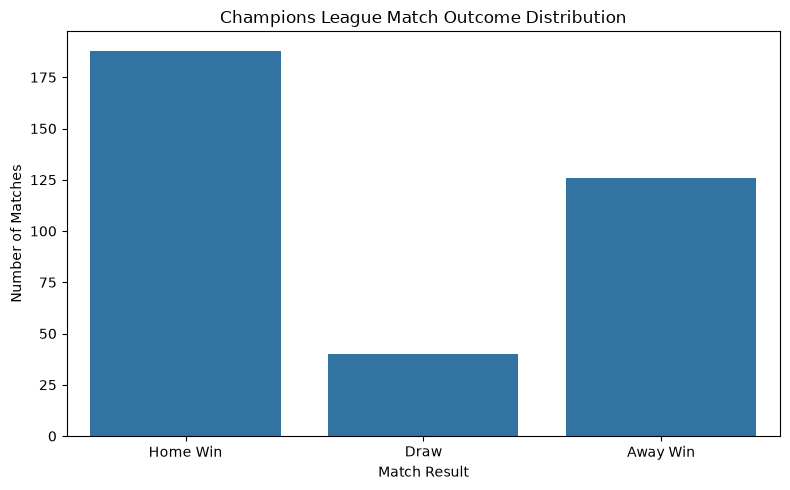

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=features_df,
    x="result",
    order=["Home Win", "Draw", "Away Win"]
)

plt.title("Champions League Match Outcome Distribution")
plt.xlabel("Match Result")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()

In [15]:
feature_columns = [
    "home_win_rate",
    "away_win_rate",
    "home_avg_goals_for",
    "home_avg_goals_against",
    "away_avg_goals_for",
    "away_avg_goals_against",
    "home_points_per_match",
    "away_points_per_match"
]

X = features_df[feature_columns]
y = features_df["result"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 283
Testing samples: 71

Training class distribution:
result
Home Win    150
Away Win    101
Draw         32
Name: count, dtype: int64

Testing class distribution:
result
Home Win    38
Away Win    25
Draw         8
Name: count, dtype: int64


In [16]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression trained successfully! 🤖⚽")

Logistic Regression trained successfully! 🤖⚽


In [17]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy = accuracy_score(y_test, logistic_predictions)

print(f"Accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, logistic_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, logistic_predictions))

Accuracy: 59.15%

Classification Report:
              precision    recall  f1-score   support

    Away Win       0.55      0.44      0.49        25
        Draw       0.00      0.00      0.00         8
    Home Win       0.61      0.82      0.70        38

    accuracy                           0.59        71
   macro avg       0.39      0.42      0.40        71
weighted avg       0.52      0.59      0.54        71


Confusion Matrix:
[[11  0 14]
 [ 2  0  6]
 [ 7  0 31]]


C:\Users\rutuj\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rutuj\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rutuj\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [18]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42
)

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_predictions)

print(f"Random Forest Accuracy: {rf_accuracy:.2%}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_predictions,
        zero_division=0
    )
)

Random Forest Accuracy: 49.30%

Classification Report:
              precision    recall  f1-score   support

    Away Win       0.48      0.60      0.54        25
        Draw       0.22      0.25      0.24         8
    Home Win       0.58      0.47      0.52        38

    accuracy                           0.49        71
   macro avg       0.43      0.44      0.43        71
weighted avg       0.51      0.49      0.49        71



In [19]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gradient_model.fit(X_train, y_train)

gradient_predictions = gradient_model.predict(X_test)

gradient_accuracy = accuracy_score(y_test, gradient_predictions)

print(f"Gradient Boosting Accuracy: {gradient_accuracy:.2%}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        gradient_predictions,
        zero_division=0
    )
)

Gradient Boosting Accuracy: 49.30%

Classification Report:
              precision    recall  f1-score   support

    Away Win       0.43      0.36      0.39        25
        Draw       0.20      0.12      0.15         8
    Home Win       0.56      0.66      0.60        38

    accuracy                           0.49        71
   macro avg       0.39      0.38      0.38        71
weighted avg       0.47      0.49      0.48        71



In [20]:
from collections import defaultdict, deque

enhanced_rows = []

for season in all_matches["season"].unique():

    season_data = all_matches[all_matches["season"] == season]

    # Keep the most recent 5 matches for every team
    team_history = defaultdict(lambda: deque(maxlen=5))

    for _, match in season_data.iterrows():

        home = match["home_team"]
        away = match["away_team"]

        # Get previous matches BEFORE the current match
        home_history = list(team_history[home])
        away_history = list(team_history[away])

        def recent_stats(history):
            if not history:
                return {
                    "points": 0.0,
                    "win_rate": 0.0,
                    "goals_for": 0.0,
                    "goals_against": 0.0,
                    "goal_difference": 0.0
                }

            return {
                "points": sum(x["points"] for x in history) / len(history),
                "win_rate": sum(x["win"] for x in history) / len(history),
                "goals_for": sum(x["goals_for"] for x in history) / len(history),
                "goals_against": sum(x["goals_against"] for x in history) / len(history),
                "goal_difference": sum(
                    x["goals_for"] - x["goals_against"]
                    for x in history
                ) / len(history)
            }

        home_recent = recent_stats(home_history)
        away_recent = recent_stats(away_history)

        enhanced_rows.append({
            "season": season,
            "home_team": home,
            "away_team": away,

            # Overall features from previous matches
            "home_win_rate": (
                sum(x["win"] for x in home_history) / len(home_history)
                if home_history else 0
            ),
            "away_win_rate": (
                sum(x["win"] for x in away_history) / len(away_history)
                if away_history else 0
            ),

            # Recent form
            "home_recent_points": home_recent["points"],
            "away_recent_points": away_recent["points"],

            "home_recent_win_rate": home_recent["win_rate"],
            "away_recent_win_rate": away_recent["win_rate"],

            "home_recent_goals_for": home_recent["goals_for"],
            "away_recent_goals_for": away_recent["goals_for"],

            "home_recent_goals_against": home_recent["goals_against"],
            "away_recent_goals_against": away_recent["goals_against"],

            "home_recent_goal_difference": home_recent["goal_difference"],
            "away_recent_goal_difference": away_recent["goal_difference"],

            # Target
            "result": match["result"]
        })

        # Update history AFTER creating the features
        home_goals = match["home_goals"]
        away_goals = match["away_goals"]

        if home_goals > away_goals:
            home_points = 3
            away_points = 0
            home_win = 1
            away_win = 0

        elif home_goals < away_goals:
            home_points = 0
            away_points = 3
            home_win = 0
            away_win = 1

        else:
            home_points = 1
            away_points = 1
            home_win = 0
            away_win = 0

        team_history[home].append({
            "points": home_points,
            "win": home_win,
            "goals_for": home_goals,
            "goals_against": away_goals
        })

        team_history[away].append({
            "points": away_points,
            "win": away_win,
            "goals_for": away_goals,
            "goals_against": home_goals
        })


enhanced_features_df = pd.DataFrame(enhanced_rows)

print("Enhanced feature engineering completed!")
print(f"Rows: {enhanced_features_df.shape[0]}")
print(f"Columns: {enhanced_features_df.shape[1]}")

display(enhanced_features_df.head(10))

Enhanced feature engineering completed!
Rows: 354
Columns: 16


,season,home_team,away_team,home_win_rate,away_win_rate,home_recent_points,away_recent_points,home_recent_win_rate,away_recent_win_rate,home_recent_goals_for,away_recent_goals_for,home_recent_goals_against,away_recent_goals_against,home_recent_goal_difference,away_recent_goal_difference,result
0,2025/26,Athletic Club (ESP),Arsenal FC (ENG),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Away Win
1,2025/26,PSV (NED),Royale Union Saint-Gilloise (BEL),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Away Win
2,2025/26,Juventus FC (ITA),Borussia Dortmund (GER),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Draw
3,2025/26,Sport Lisboa e Benfica (POR),Qarabağ Ağdam FK (AZE),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Away Win
4,2025/26,Tottenham Hotspur FC (ENG),Villarreal CF (ESP),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win
5,2025/26,Real Madrid CF (ESP),Olympique de Marseille (FRA),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win
6,2025/26,SK Slavia Praha (CZE),FK Bodø/Glimt (NOR),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Draw
7,2025/26,AFC Ajax (NED),FC Internazionale Milano (ITA),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Away Win
8,2025/26,Liverpool FC (ENG),Club Atlético de Madrid (ESP),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win
9,2025/26,Paris Saint-Germain FC (FRA),Atalanta BC (ITA),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win


In [21]:
enhanced_path = "../data/champions_league_enhanced_features.csv"

enhanced_features_df.to_csv(enhanced_path, index=False)

print("Enhanced ML dataset saved successfully!")
print(f"Rows: {enhanced_features_df.shape[0]}")
print(f"Columns: {enhanced_features_df.shape[1]}")

Enhanced ML dataset saved successfully!
Rows: 354
Columns: 16


In [22]:
enhanced_feature_columns = [
    "home_win_rate",
    "away_win_rate",
    "home_recent_points",
    "away_recent_points",
    "home_recent_win_rate",
    "away_recent_win_rate",
    "home_recent_goals_for",
    "away_recent_goals_for",
    "home_recent_goals_against",
    "away_recent_goals_against",
    "home_recent_goal_difference",
    "away_recent_goal_difference"
]

# 2024/25 = training data
train_data = enhanced_features_df[
    enhanced_features_df["season"] == "2024/25"
].copy()

# 2025/26 = unseen test season
test_data = enhanced_features_df[
    enhanced_features_df["season"] == "2025/26"
].copy()

X_train_enhanced = train_data[enhanced_feature_columns]
y_train_enhanced = train_data["result"]

X_test_enhanced = test_data[enhanced_feature_columns]
y_test_enhanced = test_data["result"]

print("Training matches:", len(X_train_enhanced))
print("Testing matches:", len(X_test_enhanced))

# -----------------------------
# Logistic Regression
# -----------------------------

enhanced_logistic = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

enhanced_logistic.fit(
    X_train_enhanced,
    y_train_enhanced
)

logistic_enhanced_pred = enhanced_logistic.predict(
    X_test_enhanced
)

# -----------------------------
# Random Forest
# -----------------------------

enhanced_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42
)

enhanced_rf.fit(
    X_train_enhanced,
    y_train_enhanced
)

rf_enhanced_pred = enhanced_rf.predict(
    X_test_enhanced
)

# -----------------------------
# Gradient Boosting
# -----------------------------

enhanced_gradient = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

enhanced_gradient.fit(
    X_train_enhanced,
    y_train_enhanced
)

gradient_enhanced_pred = enhanced_gradient.predict(
    X_test_enhanced
)

# -----------------------------
# Compare models
# -----------------------------

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test_enhanced, logistic_enhanced_pred),
        accuracy_score(y_test_enhanced, rf_enhanced_pred),
        accuracy_score(y_test_enhanced, gradient_enhanced_pred)
    ]
})

model_results["Accuracy"] = (
    model_results["Accuracy"] * 100
).round(2)

display(model_results)

Training matches: 178
Testing matches: 176


,Model,Accuracy
0,Logistic Regression,43.75
1,Random Forest,48.86
2,Gradient Boosting,53.41


In [23]:
from pathlib import Path

data_path_2023 = Path("../data/champions_league_2023_24.txt")

with open(data_path_2023, "r", encoding="utf-8") as file:
    lines_2023 = file.readlines()

print(f"Total lines: {len(lines_2023)}")

for i, line in enumerate(lines_2023[:30], start=1):
    print(f"{i}: {line.rstrip()}")

Total lines: 191
1: = UEFA Champions League 2023/24
2: 
3: # Date       Tue Sep 19 2023 - Sat Jun 1 2024 (256d)
4: # Teams      32
5: # Matches    125
6: # Stages     Group (96)  Finals (29)
7: 
8: 
9: 
10: ▪ Group, Matchday 1
11:   Tue Sep 19 2023
12:     18:45  AC Milan (ITA)          v Newcastle United FC (ENG)  0-0
13:            BSC Young Boys (SUI)    v RB Leipzig (GER)         1-3 (1-1)
14:     21:00  SS Lazio (ITA)          v Club Atlético de Madrid (ESP)  1-1 (0-1)
15:            Feyenoord Rotterdam (NED) v Celtic FC (SCO)          2-0 (1-0)
16:            Paris Saint-Germain FC (FRA) v Borussia Dortmund (GER)  2-0 (0-0)
17:            Manchester City FC (ENG) v FK Crvena Zvezda (SRB)   3-1 (0-1)
18:            FC Barcelona (ESP)      v Royal Antwerp FC (BEL)   5-0 (3-0)
19:            FK Shakhtar Donetsk (UKR) v FC Porto (POR)           1-3 (1-3)
20:   Wed Sep 20
21:     18:45  Real Madrid CF (ESP)    v 1. FC Union Berlin (GER)  1-0 (0-0)
22:            Galatasaray SK (TUR)  

In [24]:
matches_2023 = []

for line in lines_2023:
    line = line.strip()

    if " v " not in line:
        continue

    # Match with full-time + half-time score
    match = re.search(
        r"^(?:\d{2}:\d{2}\s+)?(.+?)\s+v\s+(.+?)\s+(\d+)-(\d+)\s+\((\d+)-(\d+)\)$",
        line
    )

    # Match with only full-time score, e.g. 0-0
    if not match:
        match = re.search(
            r"^(?:\d{2}:\d{2}\s+)?(.+?)\s+v\s+(.+?)\s+(\d+)-(\d+)$",
            line
        )

        if match:
            home_team = match.group(1).strip()
            away_team = match.group(2).strip()
            home_goals = int(match.group(3))
            away_goals = int(match.group(4))

            home_ht = np.nan
            away_ht = np.nan

    else:
        home_team = match.group(1).strip()
        away_team = match.group(2).strip()
        home_goals = int(match.group(3))
        away_goals = int(match.group(4))
        home_ht = int(match.group(5))
        away_ht = int(match.group(6))

    if home_goals > away_goals:
        result = "Home Win"
    elif home_goals < away_goals:
        result = "Away Win"
    else:
        result = "Draw"

    matches_2023.append({
        "home_team": home_team,
        "away_team": away_team,
        "home_goals": home_goals,
        "away_goals": away_goals,
        "home_ht_goals": home_ht,
        "away_ht_goals": away_ht,
        "result": result
    })

matches_2023_df = pd.DataFrame(matches_2023)

print(f"2023/24 matches parsed: {len(matches_2023_df)}")
print(f"Missing half-time scores:")
print(matches_2023_df[["home_ht_goals", "away_ht_goals"]].isna().sum())

display(matches_2023_df.head(10))

2023/24 matches parsed: 125
Missing half-time scores:
home_ht_goals    5
away_ht_goals    5
dtype: int64


,home_team,away_team,home_goals,away_goals,home_ht_goals,away_ht_goals,result
0,AC Milan (ITA),Newcastle United FC (ENG),0,0,NaN,NaN,Draw
1,BSC Young Boys (SUI),RB Leipzig (GER),1,3,1.0,1.0,Away Win
2,SS Lazio (ITA),Club Atlético de Madrid (ESP),1,1,0.0,1.0,Draw
3,Feyenoord Rotterdam (NED),Celtic FC (SCO),2,0,1.0,0.0,Home Win
4,Paris Saint-Germain FC (FRA),Borussia Dortmund (GER),2,0,0.0,0.0,Home Win
5,Manchester City FC (ENG),FK Crvena Zvezda (SRB),3,1,0.0,1.0,Home Win
6,FC Barcelona (ESP),Royal Antwerp FC (BEL),5,0,3.0,0.0,Home Win
7,FK Shakhtar Donetsk (UKR),FC Porto (POR),1,3,1.0,3.0,Away Win
8,Real Madrid CF (ESP),1. FC Union Berlin (GER),1,0,0.0,0.0,Home Win
9,Galatasaray SK (TUR),FC København (DEN),2,2,0.0,1.0,Draw


In [25]:
# Add the season label to the new dataset
matches_2023_df["season"] = "2023/24"

# Make sure the existing datasets have season labels
matches_2024_df["season"] = "2024/25"
matches_df["season"] = "2025/26"

# Combine all three seasons
all_matches_3seasons = pd.concat(
    [
        matches_2023_df,
        matches_2024_df,
        matches_df
    ],
    ignore_index=True
)

print("Combined dataset created!")
print(f"Total matches: {len(all_matches_3seasons)}")
print("\nMatches by season:")
print(all_matches_3seasons["season"].value_counts().sort_index())

display(all_matches_3seasons.head())

Combined dataset created!
Total matches: 479

Matches by season:
season
2023/24    125
2024/25    178
2025/26    176
Name: count, dtype: int64


,home_team,away_team,home_goals,away_goals,home_ht_goals,away_ht_goals,result,season
0,AC Milan (ITA),Newcastle United FC (ENG),0,0,NaN,NaN,Draw,2023/24
1,BSC Young Boys (SUI),RB Leipzig (GER),1,3,1.0,1.0,Away Win,2023/24
2,SS Lazio (ITA),Club Atlético de Madrid (ESP),1,1,0.0,1.0,Draw,2023/24
3,Feyenoord Rotterdam (NED),Celtic FC (SCO),2,0,1.0,0.0,Home Win,2023/24
4,Paris Saint-Germain FC (FRA),Borussia Dortmund (GER),2,0,0.0,0.0,Home Win,2023/24


In [26]:
from collections import defaultdict, deque

enhanced_rows_3seasons = []

# Process seasons in chronological order
season_order = ["2023/24", "2024/25", "2025/26"]

for season in season_order:

    season_data = all_matches_3seasons[
        all_matches_3seasons["season"] == season
    ]

    # Store each team's most recent 5 matches
    team_history = defaultdict(lambda: deque(maxlen=5))

    for _, match in season_data.iterrows():

        home = match["home_team"]
        away = match["away_team"]

        home_history = list(team_history[home])
        away_history = list(team_history[away])

        # Function to calculate recent form
        def recent_stats(history):

            if not history:
                return {
                    "points": 0.0,
                    "win_rate": 0.0,
                    "goals_for": 0.0,
                    "goals_against": 0.0,
                    "goal_difference": 0.0
                }

            return {
                "points": sum(x["points"] for x in history) / len(history),

                "win_rate": sum(
                    x["win"] for x in history
                ) / len(history),

                "goals_for": sum(
                    x["goals_for"] for x in history
                ) / len(history),

                "goals_against": sum(
                    x["goals_against"] for x in history
                ) / len(history),

                "goal_difference": sum(
                    x["goals_for"] - x["goals_against"]
                    for x in history
                ) / len(history)
            }

        home_recent = recent_stats(home_history)
        away_recent = recent_stats(away_history)

        # Save ONLY information available before this match
        enhanced_rows_3seasons.append({
            "season": season,

            "home_team": home,
            "away_team": away,

            "home_recent_points": home_recent["points"],
            "away_recent_points": away_recent["points"],

            "home_recent_win_rate": home_recent["win_rate"],
            "away_recent_win_rate": away_recent["win_rate"],

            "home_recent_goals_for": home_recent["goals_for"],
            "away_recent_goals_for": away_recent["goals_for"],

            "home_recent_goals_against": home_recent["goals_against"],
            "away_recent_goals_against": away_recent["goals_against"],

            "home_recent_goal_difference": home_recent["goal_difference"],
            "away_recent_goal_difference": away_recent["goal_difference"],

            "result": match["result"]
        })

        # Determine result statistics AFTER creating features
        home_goals = match["home_goals"]
        away_goals = match["away_goals"]

        if home_goals > away_goals:

            home_points = 3
            away_points = 0

            home_win = 1
            away_win = 0

        elif home_goals < away_goals:

            home_points = 0
            away_points = 3

            home_win = 0
            away_win = 1

        else:

            home_points = 1
            away_points = 1

            home_win = 0
            away_win = 0

        # Add this match to each team's history
        team_history[home].append({
            "points": home_points,
            "win": home_win,
            "goals_for": home_goals,
            "goals_against": away_goals
        })

        team_history[away].append({
            "points": away_points,
            "win": away_win,
            "goals_for": away_goals,
            "goals_against": home_goals
        })


enhanced_features_3seasons = pd.DataFrame(enhanced_rows_3seasons)

print("Enhanced feature engineering completed!")
print(f"Rows: {len(enhanced_features_3seasons)}")
print(f"Columns: {len(enhanced_features_3seasons.columns)}")

display(enhanced_features_3seasons.head(10))

Enhanced feature engineering completed!
Rows: 479
Columns: 14


,season,home_team,away_team,home_recent_points,away_recent_points,home_recent_win_rate,away_recent_win_rate,home_recent_goals_for,away_recent_goals_for,home_recent_goals_against,away_recent_goals_against,home_recent_goal_difference,away_recent_goal_difference,result
0,2023/24,AC Milan (ITA),Newcastle United FC (ENG),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Draw
1,2023/24,BSC Young Boys (SUI),RB Leipzig (GER),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Away Win
2,2023/24,SS Lazio (ITA),Club Atlético de Madrid (ESP),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Draw
3,2023/24,Feyenoord Rotterdam (NED),Celtic FC (SCO),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win
4,2023/24,Paris Saint-Germain FC (FRA),Borussia Dortmund (GER),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win
5,2023/24,Manchester City FC (ENG),FK Crvena Zvezda (SRB),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win
6,2023/24,FC Barcelona (ESP),Royal Antwerp FC (BEL),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win
7,2023/24,FK Shakhtar Donetsk (UKR),FC Porto (POR),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Away Win
8,2023/24,Real Madrid CF (ESP),1. FC Union Berlin (GER),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win
9,2023/24,Galatasaray SK (TUR),FC København (DEN),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Draw


In [27]:
enhanced_features_3seasons.to_csv(
    "data/champions_league_enhanced_features_3seasons.csv",
    index=False
)

print("3-season enhanced features saved successfully! ⚽")
print("File: data/champions_league_enhanced_features_3seasons.csv")

OSError: Cannot save file into a non-existent directory: 'data'

In [28]:
import os

print("Current Jupyter folder:")
print(os.getcwd())

print("\nFiles/folders here:")
print(os.listdir())

Current Jupyter folder:
C:\Users\rutuj\Documents\Football_Match_ML\notebooks

Files/folders here:
['.ipynb_checkpoints', 'Football_Match_ML.ipynb']


In [29]:
enhanced_features_3seasons.to_csv(
    "../data/champions_league_enhanced_features_3seasons.csv",
    index=False
)

print("3-season enhanced features saved successfully! ⚽")
print("File: ../data/champions_league_enhanced_features_3seasons.csv")

3-season enhanced features saved successfully! ⚽
File: ../data/champions_league_enhanced_features_3seasons.csv


In [30]:
# Features we will use for ML
feature_columns_3seasons = [
    "home_recent_points",
    "away_recent_points",
    "home_recent_win_rate",
    "away_recent_win_rate",
    "home_recent_goals_for",
    "away_recent_goals_for",
    "home_recent_goals_against",
    "away_recent_goals_against",
    "home_recent_goal_difference",
    "away_recent_goal_difference"
]

# Training data: older seasons
train_data = enhanced_features_3seasons[
    enhanced_features_3seasons["season"].isin(["2023/24", "2024/25"])
]

# Testing data: newest completed season
test_data = enhanced_features_3seasons[
    enhanced_features_3seasons["season"] == "2025/26"
]

# Create X and y
X_train = train_data[feature_columns_3seasons]
y_train = train_data["result"]

X_test = test_data[feature_columns_3seasons]
y_test = test_data["result"]

print("Training and testing data prepared! ⚽🤖")
print()
print(f"Training matches: {len(X_train)}")
print(f"Testing matches: {len(X_test)}")

print("\nTraining seasons:")
print(train_data["season"].value_counts().sort_index())

print("\nTesting season:")
print(test_data["season"].value_counts())

print("\nTraining result distribution:")
print(y_train.value_counts())

print("\nTesting result distribution:")
print(y_test.value_counts())

Training and testing data prepared! ⚽🤖

Training matches: 303
Testing matches: 176

Training seasons:
season
2023/24    125
2024/25    178
Name: count, dtype: int64

Testing season:
season
2025/26    176
Name: count, dtype: int64

Training result distribution:
result
Home Win    156
Away Win    103
Draw         44
Name: count, dtype: int64

Testing result distribution:
result
Home Win    92
Away Win    61
Draw        23
Name: count, dtype: int64


In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# ==============================
# 1. LOGISTIC REGRESSION
# ==============================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logistic_model_3 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model_3.fit(X_train_scaled, y_train)

logistic_pred = logistic_model_3.predict(X_test_scaled)

logistic_accuracy = accuracy_score(
    y_test,
    logistic_pred
)


# ==============================
# 2. RANDOM FOREST
# ==============================

random_forest_model_3 = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42
)

random_forest_model_3.fit(X_train, y_train)

random_forest_pred = random_forest_model_3.predict(X_test)

random_forest_accuracy = accuracy_score(
    y_test,
    random_forest_pred
)


# ==============================
# 3. GRADIENT BOOSTING
# ==============================

gradient_model_3 = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gradient_model_3.fit(X_train, y_train)

gradient_pred = gradient_model_3.predict(X_test)

gradient_accuracy = accuracy_score(
    y_test,
    gradient_pred
)


# ==============================
# DISPLAY RESULTS
# ==============================

print("MODEL TRAINING COMPLETED! ⚽🤖")
print()

print(f"Logistic Regression Accuracy:  {logistic_accuracy:.2%}")
print(f"Random Forest Accuracy:       {random_forest_accuracy:.2%}")
print(f"Gradient Boosting Accuracy:   {gradient_accuracy:.2%}")

MODEL TRAINING COMPLETED! ⚽🤖

Logistic Regression Accuracy:  45.45%
Random Forest Accuracy:       44.89%
Gradient Boosting Accuracy:   55.68%


In [32]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ==============================
# MAJORITY CLASS BASELINE
# ==============================

majority_class = y_train.value_counts().idxmax()

baseline_predictions = np.full(
    len(y_test),
    majority_class
)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print("MAJORITY CLASS BASELINE")
print("-----------------------")
print(f"Baseline class: {majority_class}")
print(f"Baseline accuracy: {baseline_accuracy:.2%}")


# ==============================
# MODEL COMPARISON
# ==============================

models_predictions = {
    "Logistic Regression": logistic_pred,
    "Random Forest": random_forest_pred,
    "Gradient Boosting": gradient_pred
}

print("\nMODEL EVALUATION")
print("================")

for model_name, predictions in models_predictions.items():

    accuracy = accuracy_score(y_test, predictions)

    balanced_acc = balanced_accuracy_score(
        y_test,
        predictions
    )

    macro_f1 = f1_score(
        y_test,
        predictions,
        average="macro"
    )

    print(f"\n{model_name}")
    print(f"Accuracy:          {accuracy:.2%}")
    print(f"Balanced Accuracy: {balanced_acc:.2%}")
    print(f"Macro F1 Score:    {macro_f1:.2%}")


# ==============================
# GRADIENT BOOSTING REPORT
# ==============================

print("\n" + "=" * 50)
print("GRADIENT BOOSTING - CLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        y_test,
        gradient_pred,
        zero_division=0
    )
)


# ==============================
# CONFUSION MATRIX
# ==============================

cm = confusion_matrix(
    y_test,
    gradient_pred,
    labels=["Home Win", "Draw", "Away Win"]
)

print("GRADIENT BOOSTING - CONFUSION MATRIX")
print("-------------------------------------")

cm_df = pd.DataFrame(
    cm,
    index=["Actual Home Win", "Actual Draw", "Actual Away Win"],
    columns=["Predicted Home Win", "Predicted Draw", "Predicted Away Win"]
)

display(cm_df)

MAJORITY CLASS BASELINE
-----------------------
Baseline class: Home Win
Baseline accuracy: 52.27%

MODEL EVALUATION

Logistic Regression
Accuracy:          45.45%
Balanced Accuracy: 39.39%
Macro F1 Score:    39.12%

Random Forest
Accuracy:          44.89%
Balanced Accuracy: 38.13%
Macro F1 Score:    38.22%

Gradient Boosting
Accuracy:          55.68%
Balanced Accuracy: 40.29%
Macro F1 Score:    38.23%

GRADIENT BOOSTING - CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Away Win       0.54      0.43      0.48        61
        Draw       0.00      0.00      0.00        23
    Home Win       0.59      0.78      0.67        92

    accuracy                           0.56       176
   macro avg       0.38      0.40      0.38       176
weighted avg       0.49      0.56      0.52       176

GRADIENT BOOSTING - CONFUSION MATRIX
-------------------------------------


,Predicted Home Win,Predicted Draw,Predicted Away Win
Actual Home Win,72,2,18
Actual Draw,19,0,4
Actual Away Win,32,3,26


In [33]:
# Create a copy so we keep the original dataset safe
model_features_df = enhanced_features_3seasons.copy()

# Difference between home and away team form
model_features_df["points_difference"] = (
    model_features_df["home_recent_points"]
    - model_features_df["away_recent_points"]
)

model_features_df["win_rate_difference"] = (
    model_features_df["home_recent_win_rate"]
    - model_features_df["away_recent_win_rate"]
)

model_features_df["goals_for_difference"] = (
    model_features_df["home_recent_goals_for"]
    - model_features_df["away_recent_goals_for"]
)

model_features_df["goals_against_difference"] = (
    model_features_df["home_recent_goals_against"]
    - model_features_df["away_recent_goals_against"]
)

model_features_df["goal_difference_difference"] = (
    model_features_df["home_recent_goal_difference"]
    - model_features_df["away_recent_goal_difference"]
)

# Display the new features
new_difference_columns = [
    "home_team",
    "away_team",
    "points_difference",
    "win_rate_difference",
    "goals_for_difference",
    "goals_against_difference",
    "goal_difference_difference",
    "result"
]

display(
    model_features_df[new_difference_columns].head(10)
)

print("Matchup-difference features created successfully! ⚽")

,home_team,away_team,points_difference,win_rate_difference,goals_for_difference,goals_against_difference,goal_difference_difference,result
0,AC Milan (ITA),Newcastle United FC (ENG),0.0,0.0,0.0,0.0,0.0,Draw
1,BSC Young Boys (SUI),RB Leipzig (GER),0.0,0.0,0.0,0.0,0.0,Away Win
2,SS Lazio (ITA),Club Atlético de Madrid (ESP),0.0,0.0,0.0,0.0,0.0,Draw
3,Feyenoord Rotterdam (NED),Celtic FC (SCO),0.0,0.0,0.0,0.0,0.0,Home Win
4,Paris Saint-Germain FC (FRA),Borussia Dortmund (GER),0.0,0.0,0.0,0.0,0.0,Home Win
5,Manchester City FC (ENG),FK Crvena Zvezda (SRB),0.0,0.0,0.0,0.0,0.0,Home Win
6,FC Barcelona (ESP),Royal Antwerp FC (BEL),0.0,0.0,0.0,0.0,0.0,Home Win
7,FK Shakhtar Donetsk (UKR),FC Porto (POR),0.0,0.0,0.0,0.0,0.0,Away Win
8,Real Madrid CF (ESP),1. FC Union Berlin (GER),0.0,0.0,0.0,0.0,0.0,Home Win
9,Galatasaray SK (TUR),FC København (DEN),0.0,0.0,0.0,0.0,0.0,Draw


Matchup-difference features created successfully! ⚽


In [34]:
# ==========================================
# IMPROVED FEATURE SET
# ==========================================

improved_feature_columns = [
    "home_recent_points",
    "away_recent_points",
    "home_recent_win_rate",
    "away_recent_win_rate",
    "home_recent_goals_for",
    "away_recent_goals_for",
    "home_recent_goals_against",
    "away_recent_goals_against",
    "home_recent_goal_difference",
    "away_recent_goal_difference",

    # New matchup-difference features
    "points_difference",
    "win_rate_difference",
    "goals_for_difference",
    "goals_against_difference",
    "goal_difference_difference"
]

# ==========================================
# TRAIN / TEST SPLIT
# ==========================================

train_data_improved = model_features_df[
    model_features_df["season"].isin(["2023/24", "2024/25"])
]

test_data_improved = model_features_df[
    model_features_df["season"] == "2025/26"
]

X_train_improved = train_data_improved[
    improved_feature_columns
]

y_train_improved = train_data_improved["result"]

X_test_improved = test_data_improved[
    improved_feature_columns
]

y_test_improved = test_data_improved["result"]


# ==========================================
# LOGISTIC REGRESSION
# ==========================================

scaler_improved = StandardScaler()

X_train_scaled_improved = scaler_improved.fit_transform(
    X_train_improved
)

X_test_scaled_improved = scaler_improved.transform(
    X_test_improved
)

logistic_improved = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_improved.fit(
    X_train_scaled_improved,
    y_train_improved
)

logistic_improved_pred = logistic_improved.predict(
    X_test_scaled_improved
)


# ==========================================
# RANDOM FOREST
# ==========================================

random_forest_improved = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42
)

random_forest_improved.fit(
    X_train_improved,
    y_train_improved
)

random_forest_improved_pred = random_forest_improved.predict(
    X_test_improved
)


# ==========================================
# GRADIENT BOOSTING
# ==========================================

gradient_improved = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gradient_improved.fit(
    X_train_improved,
    y_train_improved
)

gradient_improved_pred = gradient_improved.predict(
    X_test_improved
)


# ==========================================
# ACCURACY
# ==========================================

print("IMPROVED MODELS TRAINED! ⚽🤖")
print()

print(
    f"Logistic Regression: "
    f"{accuracy_score(y_test_improved, logistic_improved_pred):.2%}"
)

print(
    f"Random Forest:      "
    f"{accuracy_score(y_test_improved, random_forest_improved_pred):.2%}"
)

print(
    f"Gradient Boosting:  "
    f"{accuracy_score(y_test_improved, gradient_improved_pred):.2%}"
)

IMPROVED MODELS TRAINED! ⚽🤖

Logistic Regression: 43.75%
Random Forest:      44.89%
Gradient Boosting:  54.55%


In [35]:
# Get probability predictions from the original Gradient Boosting model

gradient_probabilities = gradient_model_3.predict_proba(X_test)

probability_df = pd.DataFrame(
    gradient_probabilities,
    columns=gradient_model_3.classes_
)

# Add the actual result and predicted result
probability_df["Actual Result"] = y_test.values
probability_df["Predicted Result"] = gradient_model_3.predict(X_test)

# Show probabilities as percentages
for column in gradient_model_3.classes_:
    probability_df[column] = (
        probability_df[column] * 100
    ).round(2)

print("Gradient Boosting prediction probabilities:")
display(probability_df.head(10))

Gradient Boosting prediction probabilities:


,Away Win,Draw,Home Win,Actual Result,Predicted Result
0,30.99,15.85,53.15,Away Win,Home Win
1,30.99,15.85,53.15,Away Win,Home Win
2,30.99,15.85,53.15,Draw,Home Win
3,30.99,15.85,53.15,Away Win,Home Win
4,30.99,15.85,53.15,Home Win,Home Win
5,30.99,15.85,53.15,Home Win,Home Win
6,30.99,15.85,53.15,Draw,Home Win
7,30.99,15.85,53.15,Away Win,Home Win
8,30.99,15.85,53.15,Home Win,Home Win
9,30.99,15.85,53.15,Home Win,Home Win


In [36]:
print("Number of unique feature combinations in test data:")

print(
    X_test.drop_duplicates().shape[0],
    "unique rows out of",
    len(X_test)
)

print("\nFeature variation:")
display(
    X_test.describe().T[
        ["min", "max", "mean", "std"]
    ]
)

print("\nFirst 10 test feature rows:")
display(X_test.head(10))

Number of unique feature combinations in test data:
160 unique rows out of 176

Feature variation:


,min,max,mean,std
home_recent_points,0.0,3.000000,1.306818,0.933492
away_recent_points,0.0,3.000000,1.435985,0.983373
home_recent_win_rate,0.0,1.000000,0.390814,0.320440
away_recent_win_rate,0.0,1.000000,0.433428,0.340385
home_recent_goals_for,0.0,4.333333,1.691856,1.007199
away_recent_goals_for,0.0,5.000000,1.796686,1.081632
home_recent_goals_against,0.0,5.000000,1.645739,1.050046
away_recent_goals_against,0.0,4.500000,1.518655,0.990184
home_recent_goal_difference,-4.0,3.333333,0.046117,1.447383
away_recent_goal_difference,-4.0,4.000000,0.278030,1.466921



First 10 test feature rows:


,home_recent_points,away_recent_points,home_recent_win_rate,away_recent_win_rate,home_recent_goals_for,away_recent_goals_for,home_recent_goals_against,away_recent_goals_against,home_recent_goal_difference,away_recent_goal_difference
303,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
304,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
305,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
306,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
307,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
308,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
309,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
310,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
311,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
312,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [37]:
# Check feature values after the first matchday of 2025/26

print("Rows 320–340 from the 2025/26 test data:")
display(
    enhanced_features_3seasons.iloc[320:341][
        [
            "home_team",
            "away_team",
            "home_recent_points",
            "away_recent_points",
            "home_recent_win_rate",
            "away_recent_win_rate",
            "home_recent_goals_for",
            "away_recent_goals_for",
            "result"
        ]
    ]
)

Rows 320–340 from the 2025/26 test data:


,home_team,away_team,home_recent_points,away_recent_points,home_recent_win_rate,away_recent_win_rate,home_recent_goals_for,away_recent_goals_for,result
320,Atalanta BC (ITA),Club Brugge KV (BEL),0.0,3.0,0.0,1.0,0.0,4.0,Home Win
321,FK Kairat (KAZ),Real Madrid CF (ESP),0.0,3.0,0.0,1.0,1.0,2.0,Away Win
322,Galatasaray SK (TUR),Liverpool FC (ENG),0.0,3.0,0.0,1.0,1.0,3.0,Home Win
323,Club Atlético de Madrid (ESP),Eintracht Frankfurt (GER),0.0,3.0,0.0,1.0,2.0,5.0,Home Win
324,Olympique de Marseille (FRA),AFC Ajax (NED),0.0,0.0,0.0,0.0,1.0,0.0,Home Win
325,FK Bodø/Glimt (NOR),Tottenham Hotspur FC (ENG),1.0,3.0,0.0,1.0,2.0,1.0,Draw
326,Paphos FC (CYP),FC Bayern München (GER),0.0,3.0,0.0,1.0,0.0,3.0,Away Win
327,Chelsea FC (ENG),Sport Lisboa e Benfica (POR),0.0,0.0,0.0,0.0,1.0,2.0,Home Win
328,FC Internazionale Milano (ITA),SK Slavia Praha (CZE),3.0,1.0,1.0,0.0,2.0,2.0,Home Win
329,Qarabağ Ağdam FK (AZE),FC København (DEN),3.0,1.0,1.0,0.0,3.0,2.0,Home Win


In [38]:
print("Unique feature combinations:")
print(X_test.drop_duplicates().shape[0], "out of", len(X_test))

print("\nFeature statistics:")
display(
    X_test.describe().T[
        ["min", "max", "mean", "std"]
    ]
)

Unique feature combinations:
160 out of 176

Feature statistics:


,min,max,mean,std
home_recent_points,0.0,3.000000,1.306818,0.933492
away_recent_points,0.0,3.000000,1.435985,0.983373
home_recent_win_rate,0.0,1.000000,0.390814,0.320440
away_recent_win_rate,0.0,1.000000,0.433428,0.340385
home_recent_goals_for,0.0,4.333333,1.691856,1.007199
away_recent_goals_for,0.0,5.000000,1.796686,1.081632
home_recent_goals_against,0.0,5.000000,1.645739,1.050046
away_recent_goals_against,0.0,4.500000,1.518655,0.990184
home_recent_goal_difference,-4.0,3.333333,0.046117,1.447383
away_recent_goal_difference,-4.0,4.000000,0.278030,1.466921


In [40]:
def predict_match_result(
    home_recent_points,
    away_recent_points,
    home_recent_win_rate,
    away_recent_win_rate,
    home_recent_goals_for,
    away_recent_goals_for,
    home_recent_goals_against,
    away_recent_goals_against,
    home_recent_goal_difference,
    away_recent_goal_difference
):
    
    # Create a single match input
    match_input = pd.DataFrame([{
        "home_recent_points": home_recent_points,
        "away_recent_points": away_recent_points,
        "home_recent_win_rate": home_recent_win_rate,
        "away_recent_win_rate": away_recent_win_rate,
        "home_recent_goals_for": home_recent_goals_for,
        "away_recent_goals_for": away_recent_goals_for,
        "home_recent_goals_against": home_recent_goals_against,
        "away_recent_goals_against": away_recent_goals_against,
        "home_recent_goal_difference": home_recent_goal_difference,
        "away_recent_goal_difference": away_recent_goal_difference
    }])

    # Get probabilities
    probabilities = gradient_model_3.predict_proba(
        match_input
    )[0]

    classes = gradient_model_3.classes_

    # Create readable result
    result = pd.DataFrame({
        "Outcome": classes,
        "Probability": probabilities * 100
    })

    result["Probability"] = result["Probability"].round(2)

    # Most likely outcome
    predicted_outcome = classes[np.argmax(probabilities)]

    print("Predicted outcome:", predicted_outcome)
    print()

    display(result)


print("Prediction function created successfully! ⚽🤖")

Prediction function created successfully! ⚽🤖


In [41]:
# Find the exact team names used in our dataset

city_teams = sorted(
    set(
        all_matches_3seasons[
            all_matches_3seasons["home_team"].str.contains(
                "Manchester City", case=False, na=False
            )
            |
            all_matches_3seasons["away_team"].str.contains(
                "Manchester City", case=False, na=False
            )
        ]["home_team"].tolist()
        +
        all_matches_3seasons[
            all_matches_3seasons["home_team"].str.contains(
                "Manchester City", case=False, na=False
            )
            |
            all_matches_3seasons["away_team"].str.contains(
                "Manchester City", case=False, na=False
            )
        ]["away_team"].tolist()
    )
)

barcelona_teams = sorted(
    set(
        all_matches_3seasons[
            all_matches_3seasons["home_team"].str.contains(
                "Barcelona", case=False, na=False
            )
            |
            all_matches_3seasons["away_team"].str.contains(
                "Barcelona", case=False, na=False
            )
        ]["home_team"].tolist()
        +
        all_matches_3seasons[
            all_matches_3seasons["home_team"].str.contains(
                "Barcelona", case=False, na=False
            )
            |
            all_matches_3seasons["away_team"].str.contains(
                "Barcelona", case=False, na=False
            )
        ]["away_team"].tolist()
    )
)

print("Manchester City names found:")
print(city_teams)

print("\nBarcelona names found:")
print(barcelona_teams)

Manchester City names found:
['AC Sparta Praha (CZE)', 'AS Monaco FC (MCO)', 'BSC Young Boys (SUI)', 'Bayer 04 Leverkusen (GER)', 'Borussia Dortmund (GER)', 'Club Brugge KV (BEL)', 'FC København (DEN)', 'FK Bodø/Glimt (NOR)', 'FK Crvena Zvezda (SRB)', 'Feyenoord Rotterdam (NED)', 'Galatasaray SK (TUR)', 'Juventus FC (ITA)', 'Manchester City FC (ENG)', 'Paris Saint-Germain FC (FRA)', 'RB Leipzig (GER)', 'Real Madrid CF (ESP)', 'SSC Napoli (ITA)', 'Sporting Clube de Portugal (POR)', 'Villarreal CF (ESP)', 'ŠK Slovan Bratislava (SVK)']

Barcelona names found:
['AS Monaco FC (MCO)', 'Atalanta BC (ITA)', 'BSC Young Boys (SUI)', 'Borussia Dortmund (GER)', 'Chelsea FC (ENG)', 'Club Atlético de Madrid (ESP)', 'Club Brugge KV (BEL)', 'Eintracht Frankfurt (GER)', 'FC Barcelona (ESP)', 'FC Bayern München (GER)', 'FC Internazionale Milano (ITA)', 'FC København (DEN)', 'FC Porto (POR)', 'FK Crvena Zvezda (SRB)', 'FK Shakhtar Donetsk (UKR)', 'Newcastle United FC (ENG)', 'PAE Olympiakos SFP (GRE)', '

In [42]:
# Check Manchester City matches
city_matches = all_matches_3seasons[
    (all_matches_3seasons["home_team"] == "Manchester City FC (ENG)") |
    (all_matches_3seasons["away_team"] == "Manchester City FC (ENG)")
]

# Check Barcelona matches
barcelona_matches = all_matches_3seasons[
    (all_matches_3seasons["home_team"] == "FC Barcelona (ESP)") |
    (all_matches_3seasons["away_team"] == "FC Barcelona (ESP)")
]

print("Manchester City matches:")
print(f"Total: {len(city_matches)}")
display(
    city_matches[
        [
            "season",
            "home_team",
            "away_team",
            "home_goals",
            "away_goals",
            "result"
        ]
    ]
)

print("\nBarcelona matches:")
print(f"Total: {len(barcelona_matches)}")
display(
    barcelona_matches[
        [
            "season",
            "home_team",
            "away_team",
            "home_goals",
            "away_goals",
            "result"
        ]
    ]
)

Manchester City matches:
Total: 28


,season,home_team,away_team,home_goals,away_goals,result
5,2023/24,Manchester City FC (ENG),FK Crvena Zvezda (SRB),3,1,Home Win
30,2023/24,RB Leipzig (GER),Manchester City FC (ENG),1,3,Away Win
45,2023/24,BSC Young Boys (SUI),Manchester City FC (ENG),1,3,Away Win
53,2023/24,Manchester City FC (ENG),BSC Young Boys (SUI),3,0,Home Win
70,2023/24,Manchester City FC (ENG),RB Leipzig (GER),3,2,Home Win
89,2023/24,FK Crvena Zvezda (SRB),Manchester City FC (ENG),2,3,Away Win
96,2023/24,FC København (DEN),Manchester City FC (ENG),1,3,Away Win
106,2023/24,Manchester City FC (ENG),FC København (DEN),3,1,Home Win
113,2023/24,Real Madrid CF (ESP),Manchester City FC (ENG),3,3,Draw
142,2024/25,ŠK Slovan Bratislava (SVK),Manchester City FC (ENG),0,4,Away Win



Barcelona matches:
Total: 37


,season,home_team,away_team,home_goals,away_goals,result
6,2023/24,FC Barcelona (ESP),Royal Antwerp FC (BEL),5,0,Home Win
31,2023/24,FC Porto (POR),FC Barcelona (ESP),0,1,Away Win
41,2023/24,FC Barcelona (ESP),FK Shakhtar Donetsk (UKR),2,1,Home Win
49,2023/24,FK Shakhtar Donetsk (UKR),FC Barcelona (ESP),1,0,Home Win
71,2023/24,FC Barcelona (ESP),FC Porto (POR),2,1,Home Win
94,2023/24,Royal Antwerp FC (BEL),FC Barcelona (ESP),3,2,Home Win
103,2023/24,SSC Napoli (ITA),FC Barcelona (ESP),1,1,Draw
109,2023/24,FC Barcelona (ESP),SSC Napoli (ITA),3,1,Home Win
110,2023/24,FC Barcelona (ESP),SSC Napoli (ITA),3,1,Home Win
115,2023/24,Paris Saint-Germain FC (FRA),FC Barcelona (ESP),2,3,Away Win


In [43]:
from collections import deque

def calculate_team_recent_form(matches_df, team_name, last_n=5):
    """
    Calculate a team's recent form from its previous matches.
    Only the most recent last_n matches are used.
    """

    team_matches = matches_df[
        (matches_df["home_team"] == team_name) |
        (matches_df["away_team"] == team_name)
    ].copy()

    # Keep only the most recent matches in the dataset
    team_matches = team_matches.tail(last_n)

    if len(team_matches) == 0:
        return {
            "points": 0.0,
            "win_rate": 0.0,
            "goals_for": 0.0,
            "goals_against": 0.0,
            "goal_difference": 0.0
        }

    points = 0
    wins = 0
    goals_for = 0
    goals_against = 0

    for _, match in team_matches.iterrows():

        if match["home_team"] == team_name:

            goals_for += match["home_goals"]
            goals_against += match["away_goals"]

            if match["home_goals"] > match["away_goals"]:
                points += 3
                wins += 1

            elif match["home_goals"] == match["away_goals"]:
                points += 1

        else:

            goals_for += match["away_goals"]
            goals_against += match["home_goals"]

            if match["away_goals"] > match["home_goals"]:
                points += 3
                wins += 1

            elif match["away_goals"] == match["home_goals"]:
                points += 1

    number_of_matches = len(team_matches)

    return {
        "points": points / number_of_matches,
        "win_rate": wins / number_of_matches,
        "goals_for": goals_for / number_of_matches,
        "goals_against": goals_against / number_of_matches,
        "goal_difference": (
            goals_for - goals_against
        ) / number_of_matches
    }


print("Recent-form calculator created! ⚽🤖")

Recent-form calculator created! ⚽🤖


In [44]:
import os

print("Files in the data folder:")

data_folder = "../data"

for file in os.listdir(data_folder):
    print("-", file)

Files in the data folder:
- champions_league_2023_24.txt
- champions_league_2024_25.txt
- champions_league_2025_26.txt
- champions_league_2025_26_clean.csv
- champions_league_enhanced_features.csv
- champions_league_enhanced_features_3seasons.csv
- champions_league_historical.csv
- champions_league_ml_features.csv


In [45]:
current_season_data = """2026/27 UEFA Champions League

Matchday 1

Porto 0-2 Manchester City
Barcelona 5-1 Feyenoord
"""

with open(
    "../data/champions_league_2026_27.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(current_season_data)

print("2026/27 data file created successfully! ⚽")
print("File: champions_league_2026_27.txt")

2026/27 data file created successfully! ⚽
File: champions_league_2026_27.txt


In [46]:
import re
import pandas as pd
import numpy as np

with open(
    "../data/champions_league_2026_27.txt",
    "r",
    encoding="utf-8"
) as f:
    current_lines = f.readlines()

current_matches = []

for line in current_lines:
    line = line.strip()

    if not line:
        continue

    # Look for: Home Team 0-2 Away Team
    match = re.match(
        r"^(.+?)\s+(\d+)-(\d+)\s+(.+?)$",
        line
    )

    if not match:
        continue

    home_team = match.group(1).strip()
    home_goals = int(match.group(2))
    away_goals = int(match.group(3))
    away_team = match.group(4).strip()

    if home_goals > away_goals:
        result = "Home Win"
    elif home_goals < away_goals:
        result = "Away Win"
    else:
        result = "Draw"

    current_matches.append({
        "home_team": home_team,
        "away_team": away_team,
        "home_goals": home_goals,
        "away_goals": away_goals,
        "home_ht_goals": np.nan,
        "away_ht_goals": np.nan,
        "result": result,
        "season": "2026/27"
    })

current_matches_df = pd.DataFrame(current_matches)

print("2026/27 matches parsed:", len(current_matches_df))

display(current_matches_df)

2026/27 matches parsed: 2


,home_team,away_team,home_goals,away_goals,home_ht_goals,away_ht_goals,result,season
0,Porto,Manchester City,0,2,NaN,NaN,Away Win,2026/27
1,Barcelona,Feyenoord,5,1,NaN,NaN,Home Win,2026/27


In [47]:
print("2026/27 teams:")

print(
    sorted(
        set(current_matches_df["home_team"])
        | set(current_matches_df["away_team"])
    )
)

2026/27 teams:
['Barcelona', 'Feyenoord', 'Manchester City', 'Porto']


In [48]:
# Standardize 2026/27 team names to match the historical dataset

team_name_mapping = {
    "Manchester City": "Manchester City FC (ENG)",
    "Barcelona": "FC Barcelona (ESP)",
    "Porto": "FC Porto (POR)",
    "Feyenoord": "Feyenoord Rotterdam (NED)"
}

current_matches_df["home_team"] = (
    current_matches_df["home_team"].replace(team_name_mapping)
)

current_matches_df["away_team"] = (
    current_matches_df["away_team"].replace(team_name_mapping)
)

print("Team names standardized! ⚽")

display(current_matches_df)

Team names standardized! ⚽


,home_team,away_team,home_goals,away_goals,home_ht_goals,away_ht_goals,result,season
0,FC Porto (POR),Manchester City FC (ENG),0,2,NaN,NaN,Away Win,2026/27
1,FC Barcelona (ESP),Feyenoord Rotterdam (NED),5,1,NaN,NaN,Home Win,2026/27


In [49]:
# Calculate 2026/27 current Champions League form

city_current_form = calculate_team_recent_form(
    current_matches_df,
    "Manchester City FC (ENG)",
    last_n=5
)

barcelona_current_form = calculate_team_recent_form(
    current_matches_df,
    "FC Barcelona (ESP)",
    last_n=5
)

print("2026/27 Manchester City form:")
for key, value in city_current_form.items():
    print(f"{key}: {value:.3f}")

print("\n2026/27 Barcelona form:")
for key, value in barcelona_current_form.items():
    print(f"{key}: {value:.3f}")

2026/27 Manchester City form:
points: 3.000
win_rate: 1.000
goals_for: 2.000
goals_against: 0.000
goal_difference: 2.000

2026/27 Barcelona form:
points: 3.000
win_rate: 1.000
goals_for: 5.000
goals_against: 1.000
goal_difference: 4.000


In [50]:
def predict_current_match(home_team, away_team):
    
    # Calculate current-season recent form
    home_form = calculate_team_recent_form(
        current_matches_df,
        home_team,
        last_n=5
    )
    
    away_form = calculate_team_recent_form(
        current_matches_df,
        away_team,
        last_n=5
    )
    
    # Create input in the exact feature order used during training
    match_input = pd.DataFrame([{
        "home_recent_points": home_form["points"],
        "away_recent_points": away_form["points"],
        "home_recent_win_rate": home_form["win_rate"],
        "away_recent_win_rate": away_form["win_rate"],
        "home_recent_goals_for": home_form["goals_for"],
        "away_recent_goals_for": away_form["goals_for"],
        "home_recent_goals_against": home_form["goals_against"],
        "away_recent_goals_against": away_form["goals_against"],
        "home_recent_goal_difference": home_form["goal_difference"],
        "away_recent_goal_difference": away_form["goal_difference"]
    }])
    
    # Get probabilities from the trained Gradient Boosting model
    probabilities = gradient_model_3.predict_proba(match_input)[0]
    classes = gradient_model_3.classes_
    
    # Create results table
    prediction_df = pd.DataFrame({
        "Outcome": classes,
        "Probability (%)": probabilities * 100
    })
    
    prediction_df["Probability (%)"] = prediction_df["Probability (%)"].round(2)
    
    predicted_outcome = classes[np.argmax(probabilities)]
    
    print(f"Home team: {home_team}")
    print(f"Away team: {away_team}")
    print()
    print("Predicted outcome:", predicted_outcome)
    print()
    
    display(prediction_df)

In [51]:
predict_current_match(
    "Manchester City FC (ENG)",
    "FC Barcelona (ESP)"
)

Home team: Manchester City FC (ENG)
Away team: FC Barcelona (ESP)

Predicted outcome: Home Win



,Outcome,Probability (%)
0,Away Win,4.64
1,Draw,0.57
2,Home Win,94.78


In [52]:
# Find all match-like lines in the 2025/26 source file
# that our parser may have missed

with open("../data/champions_league_2025_26.txt", "r", encoding="utf-8") as f:
    lines_2025 = f.readlines()

print("Possible match lines that contain ' v ':")
print("-" * 70)

for i, line in enumerate(lines_2025):
    if " v " in line:
        print(f"{i}: {line.strip()}")

Possible match lines that contain ' v ':
----------------------------------------------------------------------
11: 18:45  Athletic Club (ESP)     v Arsenal FC (ENG)         0-2 (0-0)
12: PSV (NED)               v Royale Union Saint-Gilloise (BEL)  1-3 (0-2)
13: 21:00  Juventus FC (ITA)       v Borussia Dortmund (GER)  4-4 (0-0)
14: Sport Lisboa e Benfica (POR) v Qarabağ Ağdam FK (AZE)   2-3 (2-1)
15: Tottenham Hotspur FC (ENG) v Villarreal CF (ESP)      1-0 (1-0)
16: Real Madrid CF (ESP)    v Olympique de Marseille (FRA)  2-1 (1-1)
18: 18:45  SK Slavia Praha (CZE)   v FK Bodø/Glimt (NOR)      2-2 (1-0)
19: PAE Olympiakos SFP (GRE) v Paphos FC (CYP)          0-0
20: 21:00  AFC Ajax (NED)          v FC Internazionale Milano (ITA)  0-2 (0-1)
21: Liverpool FC (ENG)      v Club Atlético de Madrid (ESP)  3-2 (2-1)
22: Paris Saint-Germain FC (FRA) v Atalanta BC (ITA)        4-0 (2-0)
23: FC Bayern München (GER) v Chelsea FC (ENG)         3-1 (2-1)
25: 18:45  FC København (DEN)      v Bayer 0

In [53]:
import re
import pandas as pd

# Load the original 2025/26 file
with open("../data/champions_league_2025_26.txt", "r", encoding="utf-8") as f:
    lines = f.readlines()

parsed_matches = []

for line in lines:
    if " v " not in line:
        continue

    line = line.strip()

    # Remove time from the beginning if present
    line = re.sub(r"^\d{1,2}:\d{2}\s+", "", line)

    # Split teams from score
    match = re.match(
        r"(.+?)\s+v\s+(.+?)\s+(\d+)-(\d+)",
        line
    )

    if not match:
        continue

    home_team = match.group(1).strip()
    away_team = match.group(2).strip()
    home_goals = int(match.group(3))
    away_goals = int(match.group(4))

    # Extract the first halftime score if available
    ht_match = re.search(r"\((\d+)-(\d+)\)", line)

    if ht_match:
        home_ht_goals = int(ht_match.group(1))
        away_ht_goals = int(ht_match.group(2))
    else:
        home_ht_goals = None
        away_ht_goals = None

    # Determine result from final score
    if home_goals > away_goals:
        result = "Home Win"
    elif home_goals < away_goals:
        result = "Away Win"
    else:
        result = "Draw"

    parsed_matches.append({
        "home_team": home_team,
        "away_team": away_team,
        "home_goals": home_goals,
        "away_goals": away_goals,
        "home_ht_goals": home_ht_goals,
        "away_ht_goals": away_ht_goals,
        "result": result
    })

matches_2025_fixed_df = pd.DataFrame(parsed_matches)

print("2025/26 matches parsed:", len(matches_2025_fixed_df))
print("\nResult distribution:")
print(matches_2025_fixed_df["result"].value_counts())

display(matches_2025_fixed_df.head())

2025/26 matches parsed: 189

Result distribution:
result
Home Win    95
Away Win    61
Draw        33
Name: count, dtype: int64


,home_team,away_team,home_goals,away_goals,home_ht_goals,away_ht_goals,result
0,Athletic Club (ESP),Arsenal FC (ENG),0,2,0.0,0.0,Away Win
1,PSV (NED),Royale Union Saint-Gilloise (BEL),1,3,0.0,2.0,Away Win
2,Juventus FC (ITA),Borussia Dortmund (GER),4,4,0.0,0.0,Draw
3,Sport Lisboa e Benfica (POR),Qarabağ Ağdam FK (AZE),2,3,2.0,1.0,Away Win
4,Tottenham Hotspur FC (ENG),Villarreal CF (ESP),1,0,1.0,0.0,Home Win


In [54]:
# Replace the old 2025/26 dataset with the corrected 189-match dataset

matches_df = matches_2025_fixed_df.copy()

matches_df["season"] = "2025/26"

# Make sure the three seasons are combined correctly
matches_2023_df["season"] = "2023/24"
matches_2024_df["season"] = "2024/25"

all_matches_3seasons = pd.concat(
    [
        matches_2023_df,
        matches_2024_df,
        matches_df
    ],
    ignore_index=True
)

print("Total matches:", len(all_matches_3seasons))
print("\nMatches by season:")
print(all_matches_3seasons["season"].value_counts().sort_index())

display(all_matches_3seasons.head())

Total matches: 492

Matches by season:
season
2023/24    125
2024/25    178
2025/26    189
Name: count, dtype: int64


,home_team,away_team,home_goals,away_goals,home_ht_goals,away_ht_goals,result,season
0,AC Milan (ITA),Newcastle United FC (ENG),0,0,NaN,NaN,Draw,2023/24
1,BSC Young Boys (SUI),RB Leipzig (GER),1,3,1.0,1.0,Away Win,2023/24
2,SS Lazio (ITA),Club Atlético de Madrid (ESP),1,1,0.0,1.0,Draw,2023/24
3,Feyenoord Rotterdam (NED),Celtic FC (SCO),2,0,1.0,0.0,Home Win,2023/24
4,Paris Saint-Germain FC (FRA),Borussia Dortmund (GER),2,0,0.0,0.0,Home Win,2023/24


In [1]:
from collections import defaultdict, deque

# Make sure seasons are processed chronologically
season_order = ["2023/24", "2024/25", "2025/26"]

enhanced_rows = []

# Store each team's previous 5 matches
team_history = defaultdict(lambda: deque(maxlen=5))

for season in season_order:

    season_matches = all_matches_3seasons[
        all_matches_3seasons["season"] == season
    ].copy()

    for _, match in season_matches.iterrows():

        home_team = match["home_team"]
        away_team = match["away_team"]

        # Get ONLY previous matches before the current match
        home_history = team_history[home_team]
        away_history = team_history[away_team]

        # Function to calculate recent statistics
        def get_recent_stats(history):

            if len(history) == 0:
                return {
                    "points": 0.0,
                    "win_rate": 0.0,
                    "goals_for": 0.0,
                    "goals_against": 0.0,
                    "goal_difference": 0.0
                }

            points = sum(x["points"] for x in history)
            wins = sum(x["win"] for x in history)
            goals_for = sum(x["goals_for"] for x in history)
            goals_against = sum(x["goals_against"] for x in history)

            n = len(history)

            return {
                "points": points / n,
                "win_rate": wins / n,
                "goals_for": goals_for / n,
                "goals_against": goals_against / n,
                "goal_difference": (goals_for - goals_against) / n
            }

        home_stats = get_recent_stats(home_history)
        away_stats = get_recent_stats(away_history)

        # Store the current match with PRE-MATCH features
        enhanced_rows.append({
            "season": season,
            "home_team": home_team,
            "away_team": away_team,

            "home_recent_points": home_stats["points"],
            "away_recent_points": away_stats["points"],

            "home_recent_win_rate": home_stats["win_rate"],
            "away_recent_win_rate": away_stats["win_rate"],

            "home_recent_goals_for": home_stats["goals_for"],
            "away_recent_goals_for": away_stats["goals_for"],

            "home_recent_goals_against": home_stats["goals_against"],
            "away_recent_goals_against": away_stats["goals_against"],

            "home_recent_goal_difference": home_stats["goal_difference"],
            "away_recent_goal_difference": away_stats["goal_difference"],

            "result": match["result"]
        })

        # NOW add the current match to each team's history
        # This prevents data leakage.
        if match["home_goals"] > match["away_goals"]:
            home_points = 3
            away_points = 0
            home_win = 1
            away_win = 0

        elif match["home_goals"] < match["away_goals"]:
            home_points = 0
            away_points = 3
            home_win = 0
            away_win = 1

        else:
            home_points = 1
            away_points = 1
            home_win = 0
            away_win = 0

        team_history[home_team].append({
            "points": home_points,
            "win": home_win,
            "goals_for": match["home_goals"],
            "goals_against": match["away_goals"]
        })

        team_history[away_team].append({
            "points": away_points,
            "win": away_win,
            "goals_for": match["away_goals"],
            "goals_against": match["home_goals"]
        })


# Create final dataframe
enhanced_features_3seasons = pd.DataFrame(enhanced_rows)

print("Enhanced feature dataset created!")
print("Rows:", len(enhanced_features_3seasons))
print("Columns:", len(enhanced_features_3seasons.columns))

display(enhanced_features_3seasons.head())

NameError: name 'all_matches_3seasons' is not defined

In [2]:
# Recreate the corrected 3-season dataset

matches_2023_df["season"] = "2023/24"
matches_2024_df["season"] = "2024/25"
matches_df["season"] = "2025/26"

all_matches_3seasons = pd.concat(
    [
        matches_2023_df,
        matches_2024_df,
        matches_df
    ],
    ignore_index=True
)

print("Total matches:", len(all_matches_3seasons))

print("\nMatches by season:")
print(
    all_matches_3seasons["season"]
    .value_counts()
    .sort_index()
)

NameError: name 'matches_2023_df' is not defined

In [3]:
import re
import pandas as pd

def parse_champions_league_file(filepath, season_name):
    
    with open(filepath, "r", encoding="utf-8") as f:
        lines = f.readlines()

    parsed_matches = []

    for line in lines:
        
        if " v " not in line:
            continue

        line = line.strip()

        # Remove time from the beginning
        line = re.sub(r"^\d{1,2}:\d{2}\s+", "", line)

        # Extract teams and final score
        match = re.match(
            r"(.+?)\s+v\s+(.+?)\s+(\d+)-(\d+)",
            line
        )

        if not match:
            continue

        home_team = match.group(1).strip()
        away_team = match.group(2).strip()

        home_goals = int(match.group(3))
        away_goals = int(match.group(4))

        # Extract halftime score when available
        ht_match = re.search(r"\((\d+)-(\d+)\)", line)

        if ht_match:
            home_ht_goals = int(ht_match.group(1))
            away_ht_goals = int(ht_match.group(2))
        else:
            home_ht_goals = None
            away_ht_goals = None

        # Determine result
        if home_goals > away_goals:
            result = "Home Win"
        elif home_goals < away_goals:
            result = "Away Win"
        else:
            result = "Draw"

        parsed_matches.append({
            "home_team": home_team,
            "away_team": away_team,
            "home_goals": home_goals,
            "away_goals": away_goals,
            "home_ht_goals": home_ht_goals,
            "away_ht_goals": away_ht_goals,
            "result": result,
            "season": season_name
        })

    return pd.DataFrame(parsed_matches)


# Parse all three seasons
matches_2023_df = parse_champions_league_file(
    "../data/champions_league_2023_24.txt",
    "2023/24"
)

matches_2024_df = parse_champions_league_file(
    "../data/champions_league_2024_25.txt",
    "2024/25"
)

matches_df = parse_champions_league_file(
    "../data/champions_league_2025_26.txt",
    "2025/26"
)


# Combine all three seasons
all_matches_3seasons = pd.concat(
    [
        matches_2023_df,
        matches_2024_df,
        matches_df
    ],
    ignore_index=True
)


print("Dataset rebuilt successfully! ⚽")
print()
print("Matches by season:")
print(
    all_matches_3seasons["season"]
    .value_counts()
    .sort_index()
)

print()
print("Total matches:", len(all_matches_3seasons))

Dataset rebuilt successfully! ⚽

Matches by season:
season
2023/24    125
2024/25    189
2025/26    189
Name: count, dtype: int64

Total matches: 503


In [4]:
from collections import defaultdict, deque

season_order = ["2023/24", "2024/25", "2025/26"]

enhanced_rows = []

# Store each team's previous 5 matches
team_history = defaultdict(lambda: deque(maxlen=5))


for season in season_order:

    season_matches = all_matches_3seasons[
        all_matches_3seasons["season"] == season
    ].copy()

    for _, match in season_matches.iterrows():

        home_team = match["home_team"]
        away_team = match["away_team"]

        # Previous matches BEFORE the current match
        home_history = team_history[home_team]
        away_history = team_history[away_team]

        def get_recent_stats(history):

            if len(history) == 0:
                return {
                    "points": 0.0,
                    "win_rate": 0.0,
                    "goals_for": 0.0,
                    "goals_against": 0.0,
                    "goal_difference": 0.0
                }

            points = sum(x["points"] for x in history)
            wins = sum(x["win"] for x in history)
            goals_for = sum(x["goals_for"] for x in history)
            goals_against = sum(x["goals_against"] for x in history)

            n = len(history)

            return {
                "points": points / n,
                "win_rate": wins / n,
                "goals_for": goals_for / n,
                "goals_against": goals_against / n,
                "goal_difference": (goals_for - goals_against) / n
            }

        home_stats = get_recent_stats(home_history)
        away_stats = get_recent_stats(away_history)

        # Save PRE-MATCH features
        enhanced_rows.append({
            "season": season,
            "home_team": home_team,
            "away_team": away_team,

            "home_recent_points": home_stats["points"],
            "away_recent_points": away_stats["points"],

            "home_recent_win_rate": home_stats["win_rate"],
            "away_recent_win_rate": away_stats["win_rate"],

            "home_recent_goals_for": home_stats["goals_for"],
            "away_recent_goals_for": away_stats["goals_for"],

            "home_recent_goals_against": home_stats["goals_against"],
            "away_recent_goals_against": away_stats["goals_against"],

            "home_recent_goal_difference": home_stats["goal_difference"],
            "away_recent_goal_difference": away_stats["goal_difference"],

            "result": match["result"]
        })

        # Add current match to history ONLY AFTER
        # calculating the features.
        if match["home_goals"] > match["away_goals"]:
            home_points = 3
            away_points = 0
            home_win = 1
            away_win = 0

        elif match["home_goals"] < match["away_goals"]:
            home_points = 0
            away_points = 3
            home_win = 0
            away_win = 1

        else:
            home_points = 1
            away_points = 1
            home_win = 0
            away_win = 0

        team_history[home_team].append({
            "points": home_points,
            "win": home_win,
            "goals_for": match["home_goals"],
            "goals_against": match["away_goals"]
        })

        team_history[away_team].append({
            "points": away_points,
            "win": away_win,
            "goals_for": match["away_goals"],
            "goals_against": match["home_goals"]
        })


# Create final feature dataframe
enhanced_features_3seasons = pd.DataFrame(enhanced_rows)

print("Enhanced feature dataset created! ⚽")
print("Rows:", len(enhanced_features_3seasons))
print("Columns:", len(enhanced_features_3seasons.columns))

display(enhanced_features_3seasons.head())

Enhanced feature dataset created! ⚽
Rows: 503
Columns: 14


,season,home_team,away_team,home_recent_points,away_recent_points,home_recent_win_rate,away_recent_win_rate,home_recent_goals_for,away_recent_goals_for,home_recent_goals_against,away_recent_goals_against,home_recent_goal_difference,away_recent_goal_difference,result
0,2023/24,AC Milan (ITA),Newcastle United FC (ENG),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Draw
1,2023/24,BSC Young Boys (SUI),RB Leipzig (GER),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Away Win
2,2023/24,SS Lazio (ITA),Club Atlético de Madrid (ESP),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Draw
3,2023/24,Feyenoord Rotterdam (NED),Celtic FC (SCO),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win
4,2023/24,Paris Saint-Germain FC (FRA),Borussia Dortmund (GER),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win


In [5]:
print("Total rows in all_matches_3seasons:", len(all_matches_3seasons))

print("\nMatches by season:")
print(
    all_matches_3seasons["season"]
    .value_counts()
    .sort_index()
)

print("\nRows in enhanced feature dataset:", len(enhanced_features_3seasons))

print("\nMatches by season in feature dataset:")
print(
    enhanced_features_3seasons["season"]
    .value_counts()
    .sort_index()
)

Total rows in all_matches_3seasons: 503

Matches by season:
season
2023/24    125
2024/25    189
2025/26    189
Name: count, dtype: int64

Rows in enhanced feature dataset: 503

Matches by season in feature dataset:
season
2023/24    125
2024/25    189
2025/26    189
Name: count, dtype: int64


In [6]:
enhanced_features_3seasons.to_csv(
    "../data/champions_league_enhanced_features_3seasons.csv",
    index=False
)

print("Corrected feature dataset saved! ⚽")
print("File: champions_league_enhanced_features_3seasons.csv")
print("Rows:", len(enhanced_features_3seasons))

Corrected feature dataset saved! ⚽
File: champions_league_enhanced_features_3seasons.csv
Rows: 503


In [7]:
feature_columns_3seasons = [
    "home_recent_points",
    "away_recent_points",
    "home_recent_win_rate",
    "away_recent_win_rate",
    "home_recent_goals_for",
    "away_recent_goals_for",
    "home_recent_goals_against",
    "away_recent_goals_against",
    "home_recent_goal_difference",
    "away_recent_goal_difference"
]

print("Dataset shape:", enhanced_features_3seasons.shape)

print("\nMissing values:")
print(
    enhanced_features_3seasons[
        feature_columns_3seasons + ["result"]
    ].isnull().sum()
)

print("\nTarget distribution:")
print(
    enhanced_features_3seasons["result"].value_counts()
)

Dataset shape: (503, 14)

Missing values:
home_recent_points             0
away_recent_points             0
home_recent_win_rate           0
away_recent_win_rate           0
home_recent_goals_for          0
away_recent_goals_for          0
home_recent_goals_against      0
away_recent_goals_against      0
home_recent_goal_difference    0
away_recent_goal_difference    0
result                         0
dtype: int64

Target distribution:
result
Home Win    251
Away Win    167
Draw         85
Name: count, dtype: int64


In [8]:
# Chronological train/test split

train_data = enhanced_features_3seasons[
    enhanced_features_3seasons["season"].isin(["2023/24", "2024/25"])
].copy()

test_data = enhanced_features_3seasons[
    enhanced_features_3seasons["season"] == "2025/26"
].copy()

X_train = train_data[feature_columns_3seasons]
y_train = train_data["result"]

X_test = test_data[feature_columns_3seasons]
y_test = test_data["result"]

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))

print("\nTraining seasons:")
print(train_data["season"].value_counts().sort_index())

print("\nTesting season:")
print(test_data["season"].value_counts())

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training matches: 314
Testing matches: 189

Training seasons:
season
2023/24    125
2024/25    189
Name: count, dtype: int64

Testing season:
season
2025/26    189
Name: count, dtype: int64

Training target distribution:
result
Home Win    156
Away Win    106
Draw         52
Name: count, dtype: int64

Testing target distribution:
result
Home Win    95
Away Win    61
Draw        33
Name: count, dtype: int64


In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# --------------------------------------------------
# 1. Logistic Regression
# --------------------------------------------------

scaler_final = StandardScaler()

X_train_scaled = scaler_final.fit_transform(X_train)
X_test_scaled = scaler_final.transform(X_test)

logistic_model_final = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model_final.fit(X_train_scaled, y_train)

logistic_predictions = logistic_model_final.predict(X_test_scaled)

logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)


# --------------------------------------------------
# 2. Random Forest
# --------------------------------------------------

random_forest_model_final = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42
)

random_forest_model_final.fit(X_train, y_train)

random_forest_predictions = random_forest_model_final.predict(X_test)

random_forest_accuracy = accuracy_score(
    y_test,
    random_forest_predictions
)


# --------------------------------------------------
# 3. Gradient Boosting
# --------------------------------------------------

gradient_model_final = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gradient_model_final.fit(X_train, y_train)

gradient_predictions = gradient_model_final.predict(X_test)

gradient_accuracy = accuracy_score(
    y_test,
    gradient_predictions
)


# --------------------------------------------------
# Results
# --------------------------------------------------

print("FINAL MODEL TRAINING COMPLETED! ⚽🤖")
print()
print(f"Logistic Regression Accuracy: {logistic_accuracy * 100:.2f}%")
print(f"Random Forest Accuracy:       {random_forest_accuracy * 100:.2f}%")
print(f"Gradient Boosting Accuracy:   {gradient_accuracy * 100:.2f}%")

FINAL MODEL TRAINING COMPLETED! ⚽🤖

Logistic Regression Accuracy: 42.86%
Random Forest Accuracy:       40.74%
Gradient Boosting Accuracy:   49.21%


In [10]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# --------------------------------------------------
# Calculate metrics
# --------------------------------------------------

models = {
    "Logistic Regression": logistic_predictions,
    "Random Forest": random_forest_predictions,
    "Gradient Boosting": gradient_predictions
}

evaluation_results = []

for model_name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)

    balanced_accuracy = balanced_accuracy_score(
        y_test,
        predictions
    )

    macro_f1 = f1_score(
        y_test,
        predictions,
        average="macro"
    )

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": round(accuracy * 100, 2),
        "Balanced Accuracy": round(balanced_accuracy * 100, 2),
        "Macro F1": round(macro_f1 * 100, 2)
    })


evaluation_df = pd.DataFrame(evaluation_results)

print("MODEL EVALUATION")
display(evaluation_df)


# --------------------------------------------------
# Detailed report for Gradient Boosting
# --------------------------------------------------

print("\nGRADIENT BOOSTING CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        gradient_predictions
    )
)


# --------------------------------------------------
# Confusion matrix
# --------------------------------------------------

gradient_cm = confusion_matrix(
    y_test,
    gradient_predictions,
    labels=["Away Win", "Draw", "Home Win"]
)

print("\nGRADIENT BOOSTING CONFUSION MATRIX")
print("Rows = Actual")
print("Columns = Predicted")
print()

print(
    pd.DataFrame(
        gradient_cm,
        index=["Actual Away Win", "Actual Draw", "Actual Home Win"],
        columns=["Predicted Away Win", "Predicted Draw", "Predicted Home Win"]
    )
)


MODEL EVALUATION


,Model,Accuracy,Balanced Accuracy,Macro F1
0,Logistic Regression,42.86,41.00,39.70
1,Random Forest,40.74,34.67,34.19
2,Gradient Boosting,49.21,37.33,34.43



GRADIENT BOOSTING CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Away Win       0.41      0.39      0.40        61
        Draw       0.00      0.00      0.00        33
    Home Win       0.56      0.73      0.63        95

    accuracy                           0.49       189
   macro avg       0.32      0.37      0.34       189
weighted avg       0.41      0.49      0.45       189


GRADIENT BOOSTING CONFUSION MATRIX
Rows = Actual
Columns = Predicted

                 Predicted Away Win  Predicted Draw  Predicted Home Win
Actual Away Win                  24               4                  33
Actual Draw                      12               0                  21
Actual Home Win                  23               3                  69


In [11]:
from collections import defaultdict, deque

season_order = ["2023/24", "2024/25", "2025/26"]

improved_rows = []

# Store previous matches separately for home and away
team_home_history = defaultdict(lambda: deque(maxlen=5))
team_away_history = defaultdict(lambda: deque(maxlen=5))


def calculate_location_stats(history):

    if len(history) == 0:
        return {
            "win_rate": 0.0,
            "goals_for": 0.0,
            "goals_against": 0.0,
            "goal_difference": 0.0
        }

    wins = sum(x["win"] for x in history)
    goals_for = sum(x["goals_for"] for x in history)
    goals_against = sum(x["goals_against"] for x in history)

    n = len(history)

    return {
        "win_rate": wins / n,
        "goals_for": goals_for / n,
        "goals_against": goals_against / n,
        "goal_difference": (goals_for - goals_against) / n
    }


for season in season_order:

    season_matches = all_matches_3seasons[
        all_matches_3seasons["season"] == season
    ].copy()

    for _, match in season_matches.iterrows():

        home_team = match["home_team"]
        away_team = match["away_team"]

        # Existing overall recent-form features
        # from the previous 5 matches
        #
        # We reconstruct these from all previous matches
        # stored in separate histories.

        # --------------------------------------------------
        # Get previous overall history
        # --------------------------------------------------

        # Combine home + away histories for each team
        home_overall_history = list(team_home_history[home_team]) + \
                               list(team_away_history[home_team])

        away_overall_history = list(team_home_history[away_team]) + \
                               list(team_away_history[away_team])

        # Sort by match sequence and keep most recent 5
        home_overall_history = home_overall_history[-5:]
        away_overall_history = away_overall_history[-5:]

        def overall_stats(history):

            if len(history) == 0:
                return {
                    "points": 0.0,
                    "win_rate": 0.0,
                    "goals_for": 0.0,
                    "goals_against": 0.0,
                    "goal_difference": 0.0
                }

            points = sum(x["points"] for x in history)
            wins = sum(x["win"] for x in history)
            goals_for = sum(x["goals_for"] for x in history)
            goals_against = sum(x["goals_against"] for x in history)

            n = len(history)

            return {
                "points": points / n,
                "win_rate": wins / n,
                "goals_for": goals_for / n,
                "goals_against": goals_against / n,
                "goal_difference": (goals_for - goals_against) / n
            }

        home_overall = overall_stats(home_overall_history)
        away_overall = overall_stats(away_overall_history)

        # --------------------------------------------------
        # Location-specific history
        # --------------------------------------------------

        home_location = calculate_location_stats(
            team_home_history[home_team]
        )

        away_location = calculate_location_stats(
            team_away_history[away_team]
        )

        # --------------------------------------------------
        # Save features BEFORE current match
        # --------------------------------------------------

        improved_rows.append({

            "season": season,
            "home_team": home_team,
            "away_team": away_team,

            # Existing overall recent form
            "home_recent_points": home_overall["points"],
            "away_recent_points": away_overall["points"],

            "home_recent_win_rate": home_overall["win_rate"],
            "away_recent_win_rate": away_overall["win_rate"],

            "home_recent_goals_for": home_overall["goals_for"],
            "away_recent_goals_for": away_overall["goals_for"],

            "home_recent_goals_against": home_overall["goals_against"],
            "away_recent_goals_against": away_overall["goals_against"],

            "home_recent_goal_difference": home_overall["goal_difference"],
            "away_recent_goal_difference": away_overall["goal_difference"],

            # New home/away-specific features
            "home_home_win_rate": home_location["win_rate"],
            "away_away_win_rate": away_location["win_rate"],

            "home_home_goals_for": home_location["goals_for"],
            "away_away_goals_for": away_location["goals_for"],

            "home_home_goals_against": home_location["goals_against"],
            "away_away_goals_against": away_location["goals_against"],

            "home_home_goal_difference": home_location["goal_difference"],
            "away_away_goal_difference": away_location["goal_difference"],

            # Target
            "result": match["result"]
        })

        # --------------------------------------------------
        # Add current match AFTER feature calculation
        # --------------------------------------------------

        if match["home_goals"] > match["away_goals"]:

            home_points = 3
            away_points = 0
            home_win = 1
            away_win = 0

        elif match["home_goals"] < match["away_goals"]:

            home_points = 0
            away_points = 3
            home_win = 0
            away_win = 1

        else:

            home_points = 1
            away_points = 1
            home_win = 0
            away_win = 0

        # Add to HOME history
        team_home_history[home_team].append({
            "points": home_points,
            "win": home_win,
            "goals_for": match["home_goals"],
            "goals_against": match["away_goals"]
        })

        # Add to AWAY history
        team_away_history[away_team].append({
            "points": away_points,
            "win": away_win,
            "goals_for": match["away_goals"],
            "goals_against": match["home_goals"]
        })


# Create improved dataframe
improved_features_df = pd.DataFrame(improved_rows)

print("Improved feature dataset created! ⚽")
print("Rows:", len(improved_features_df))
print("Columns:", len(improved_features_df.columns))

print("\nNew features:")
display(improved_features_df.head())

Improved feature dataset created! ⚽
Rows: 503
Columns: 22

New features:


,season,home_team,away_team,home_recent_points,away_recent_points,home_recent_win_rate,away_recent_win_rate,home_recent_goals_for,away_recent_goals_for,home_recent_goals_against,...,away_recent_goal_difference,home_home_win_rate,away_away_win_rate,home_home_goals_for,away_away_goals_for,home_home_goals_against,away_away_goals_against,home_home_goal_difference,away_away_goal_difference,result
0,2023/24,AC Milan (ITA),Newcastle United FC (ENG),0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Draw
1,2023/24,BSC Young Boys (SUI),RB Leipzig (GER),0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Away Win
2,2023/24,SS Lazio (ITA),Club Atlético de Madrid (ESP),0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Draw
3,2023/24,Feyenoord Rotterdam (NED),Celtic FC (SCO),0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win
4,2023/24,Paris Saint-Germain FC (FRA),Borussia Dortmund (GER),0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win


In [12]:
from collections import defaultdict, deque

season_order = ["2023/24", "2024/25", "2025/26"]

improved_rows = []

# Three separate histories
overall_history = defaultdict(lambda: deque(maxlen=5))
home_history = defaultdict(lambda: deque(maxlen=5))
away_history = defaultdict(lambda: deque(maxlen=5))


def get_overall_stats(history):

    if len(history) == 0:
        return {
            "points": 0.0,
            "win_rate": 0.0,
            "goals_for": 0.0,
            "goals_against": 0.0,
            "goal_difference": 0.0
        }

    n = len(history)

    points = sum(x["points"] for x in history)
    wins = sum(x["win"] for x in history)
    goals_for = sum(x["goals_for"] for x in history)
    goals_against = sum(x["goals_against"] for x in history)

    return {
        "points": points / n,
        "win_rate": wins / n,
        "goals_for": goals_for / n,
        "goals_against": goals_against / n,
        "goal_difference": (goals_for - goals_against) / n
    }


def get_location_stats(history):

    if len(history) == 0:
        return {
            "win_rate": 0.0,
            "goals_for": 0.0,
            "goals_against": 0.0,
            "goal_difference": 0.0
        }

    n = len(history)

    wins = sum(x["win"] for x in history)
    goals_for = sum(x["goals_for"] for x in history)
    goals_against = sum(x["goals_against"] for x in history)

    return {
        "win_rate": wins / n,
        "goals_for": goals_for / n,
        "goals_against": goals_against / n,
        "goal_difference": (goals_for - goals_against) / n
    }


for season in season_order:

    season_matches = all_matches_3seasons[
        all_matches_3seasons["season"] == season
    ]

    for _, match in season_matches.iterrows():

        home_team = match["home_team"]
        away_team = match["away_team"]

        # ---------------------------------------------
        # PRE-MATCH statistics
        # ---------------------------------------------

        home_overall = get_overall_stats(
            overall_history[home_team]
        )

        away_overall = get_overall_stats(
            overall_history[away_team]
        )

        home_location = get_location_stats(
            home_history[home_team]
        )

        away_location = get_location_stats(
            away_history[away_team]
        )

        # ---------------------------------------------
        # Store features BEFORE current match
        # ---------------------------------------------

        improved_rows.append({

            "season": season,
            "home_team": home_team,
            "away_team": away_team,

            # Overall recent form
            "home_recent_points": home_overall["points"],
            "away_recent_points": away_overall["points"],

            "home_recent_win_rate": home_overall["win_rate"],
            "away_recent_win_rate": away_overall["win_rate"],

            "home_recent_goals_for": home_overall["goals_for"],
            "away_recent_goals_for": away_overall["goals_for"],

            "home_recent_goals_against": home_overall["goals_against"],
            "away_recent_goals_against": away_overall["goals_against"],

            "home_recent_goal_difference": home_overall["goal_difference"],
            "away_recent_goal_difference": away_overall["goal_difference"],

            # Home / Away specific form
            "home_home_win_rate": home_location["win_rate"],
            "away_away_win_rate": away_location["win_rate"],

            "home_home_goals_for": home_location["goals_for"],
            "away_away_goals_for": away_location["goals_for"],

            "home_home_goals_against": home_location["goals_against"],
            "away_away_goals_against": away_location["goals_against"],

            "home_home_goal_difference": home_location["goal_difference"],
            "away_away_goal_difference": away_location["goal_difference"],

            "result": match["result"]
        })

        # ---------------------------------------------
        # Determine current match result
        # ---------------------------------------------

        if match["home_goals"] > match["away_goals"]:

            home_points = 3
            away_points = 0
            home_win = 1
            away_win = 0

        elif match["home_goals"] < match["away_goals"]:

            home_points = 0
            away_points = 3
            home_win = 0
            away_win = 1

        else:

            home_points = 1
            away_points = 1
            home_win = 0
            away_win = 0

        # ---------------------------------------------
        # Update histories AFTER current match
        # ---------------------------------------------

        home_record = {
            "points": home_points,
            "win": home_win,
            "goals_for": match["home_goals"],
            "goals_against": match["away_goals"]
        }

        away_record = {
            "points": away_points,
            "win": away_win,
            "goals_for": match["away_goals"],
            "goals_against": match["home_goals"]
        }

        # Overall histories
        overall_history[home_team].append(home_record)
        overall_history[away_team].append(away_record)

        # Location-specific histories
        home_history[home_team].append(home_record)
        away_history[away_team].append(away_record)


# Create corrected feature dataset
improved_features_df = pd.DataFrame(improved_rows)

print("Corrected feature dataset created! ⚽")
print("Rows:", len(improved_features_df))
print("Columns:", len(improved_features_df.columns))

print("\nMissing values:")
print(
    improved_features_df.isnull().sum().sum()
)

display(improved_features_df.head())

Corrected feature dataset created! ⚽
Rows: 503
Columns: 22

Missing values:
0


,season,home_team,away_team,home_recent_points,away_recent_points,home_recent_win_rate,away_recent_win_rate,home_recent_goals_for,away_recent_goals_for,home_recent_goals_against,...,away_recent_goal_difference,home_home_win_rate,away_away_win_rate,home_home_goals_for,away_away_goals_for,home_home_goals_against,away_away_goals_against,home_home_goal_difference,away_away_goal_difference,result
0,2023/24,AC Milan (ITA),Newcastle United FC (ENG),0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Draw
1,2023/24,BSC Young Boys (SUI),RB Leipzig (GER),0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Away Win
2,2023/24,SS Lazio (ITA),Club Atlético de Madrid (ESP),0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Draw
3,2023/24,Feyenoord Rotterdam (NED),Celtic FC (SCO),0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win
4,2023/24,Paris Saint-Germain FC (FRA),Borussia Dortmund (GER),0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Home Win


In [13]:
# --------------------------------------------------
# Define the 18 improved ML features
# --------------------------------------------------

improved_feature_columns = [
    # Overall recent form
    "home_recent_points",
    "away_recent_points",
    "home_recent_win_rate",
    "away_recent_win_rate",
    "home_recent_goals_for",
    "away_recent_goals_for",
    "home_recent_goals_against",
    "away_recent_goals_against",
    "home_recent_goal_difference",
    "away_recent_goal_difference",

    # Home / away specific form
    "home_home_win_rate",
    "away_away_win_rate",
    "home_home_goals_for",
    "away_away_goals_for",
    "home_home_goals_against",
    "away_away_goals_against",
    "home_home_goal_difference",
    "away_away_goal_difference"
]


# --------------------------------------------------
# Chronological train/test split
# --------------------------------------------------

improved_train = improved_features_df[
    improved_features_df["season"].isin(
        ["2023/24", "2024/25"]
    )
].copy()

improved_test = improved_features_df[
    improved_features_df["season"] == "2025/26"
].copy()


X_train_improved = improved_train[
    improved_feature_columns
]

y_train_improved = improved_train["result"]

X_test_improved = improved_test[
    improved_feature_columns
]

y_test_improved = improved_test["result"]


print("Training matches:", len(X_train_improved))
print("Testing matches:", len(X_test_improved))


# --------------------------------------------------
# 1. Logistic Regression
# --------------------------------------------------

improved_scaler = StandardScaler()

X_train_improved_scaled = improved_scaler.fit_transform(
    X_train_improved
)

X_test_improved_scaled = improved_scaler.transform(
    X_test_improved
)

logistic_improved = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_improved.fit(
    X_train_improved_scaled,
    y_train_improved
)

logistic_improved_predictions = logistic_improved.predict(
    X_test_improved_scaled
)


# --------------------------------------------------
# 2. Random Forest
# --------------------------------------------------

random_forest_improved = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42
)

random_forest_improved.fit(
    X_train_improved,
    y_train_improved
)

random_forest_improved_predictions = (
    random_forest_improved.predict(X_test_improved)
)


# --------------------------------------------------
# 3. Gradient Boosting
# --------------------------------------------------

gradient_improved = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gradient_improved.fit(
    X_train_improved,
    y_train_improved
)

gradient_improved_predictions = (
    gradient_improved.predict(X_test_improved)
)


# --------------------------------------------------
# Accuracy comparison
# --------------------------------------------------

print("\nIMPROVED MODEL RESULTS ⚽🤖")
print()

print(
    "Logistic Regression Accuracy:",
    round(
        accuracy_score(
            y_test_improved,
            logistic_improved_predictions
        ) * 100,
        2
    ),
    "%"
)

print(
    "Random Forest Accuracy:",
    round(
        accuracy_score(
            y_test_improved,
            random_forest_improved_predictions
        ) * 100,
        2
    ),
    "%"
)

print(
    "Gradient Boosting Accuracy:",
    round(
        accuracy_score(
            y_test_improved,
            gradient_improved_predictions
        ) * 100,
        2
    ),
    "%"
)

Training matches: 314
Testing matches: 189

IMPROVED MODEL RESULTS ⚽🤖

Logistic Regression Accuracy: 44.44 %
Random Forest Accuracy: 46.03 %
Gradient Boosting Accuracy: 47.62 %


In [14]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

models_improved = {
    "Logistic Regression": logistic_improved_predictions,
    "Random Forest": random_forest_improved_predictions,
    "Gradient Boosting": gradient_improved_predictions
}

results_improved = []

for model_name, predictions in models_improved.items():

    accuracy = accuracy_score(
        y_test_improved,
        predictions
    )

    balanced_acc = balanced_accuracy_score(
        y_test_improved,
        predictions
    )

    macro_f1 = f1_score(
        y_test_improved,
        predictions,
        average="macro"
    )

    results_improved.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced_acc,
        "Macro F1": macro_f1
    })


# Create comparison table
improved_results_df = pd.DataFrame(results_improved)

print("IMPROVED MODEL EVALUATION")
print()

print(
    improved_results_df.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.2%}".format,
            "Balanced Accuracy": "{:.2%}".format,
            "Macro F1": "{:.2%}".format
        }
    )
)


# --------------------------------------------------
# Classification reports
# --------------------------------------------------

for model_name, predictions in models_improved.items():

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test_improved,
            predictions,
            labels=["Away Win", "Draw", "Home Win"],
            zero_division=0
        )
    )


# --------------------------------------------------
# Confusion matrices
# --------------------------------------------------

labels = ["Away Win", "Draw", "Home Win"]

for model_name, predictions in models_improved.items():

    cm = confusion_matrix(
        y_test_improved,
        predictions,
        labels=labels
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

IMPROVED MODEL EVALUATION

              Model Accuracy Balanced Accuracy Macro F1
Logistic Regression   44.44%            40.74%   39.90%
      Random Forest   46.03%            38.18%   37.36%
  Gradient Boosting   47.62%            36.66%   33.71%

Logistic Regression
              precision    recall  f1-score   support

    Away Win       0.41      0.56      0.47        61
        Draw       0.23      0.21      0.22        33
    Home Win       0.57      0.45      0.51        95

    accuracy                           0.44       189
   macro avg       0.40      0.41      0.40       189
weighted avg       0.46      0.44      0.44       189


Random Forest
              precision    recall  f1-score   support

    Away Win       0.39      0.48      0.43        61
        Draw       0.16      0.09      0.12        33
    Home Win       0.57      0.58      0.58        95

    accuracy                           0.46       189
   macro avg       0.37      0.38      0.37       189
weight

NameError: name 'plt' is not defined

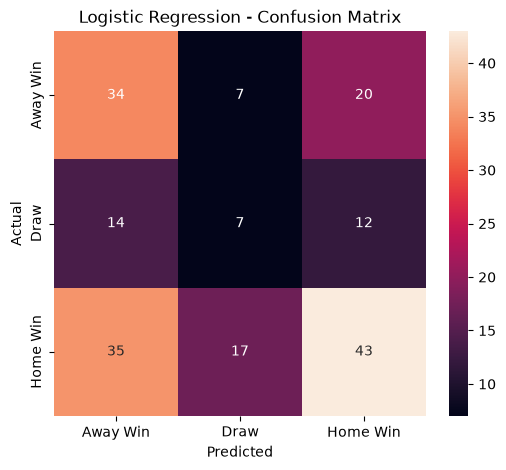

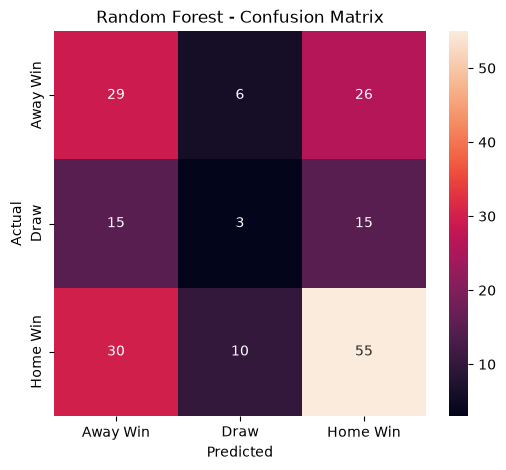

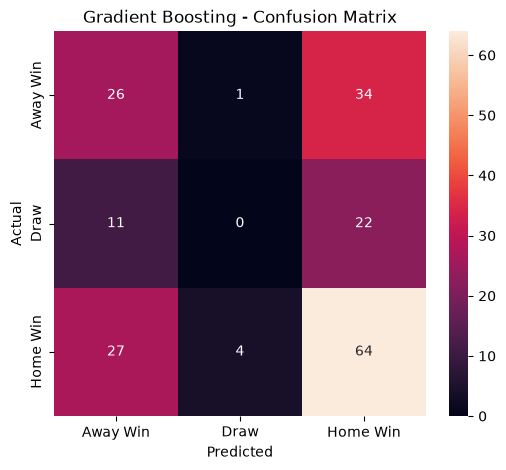

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = ["Away Win", "Draw", "Home Win"]

models_improved = {
    "Logistic Regression": logistic_improved_predictions,
    "Random Forest": random_forest_improved_predictions,
    "Gradient Boosting": gradient_improved_predictions
}

for model_name, predictions in models_improved.items():

    cm = confusion_matrix(
        y_test_improved,
        predictions,
        labels=labels
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [16]:
# Save the corrected improved feature dataset

improved_features_df.to_csv(
    "../data/champions_league_improved_features_3seasons.csv",
    index=False
)

print("Improved feature dataset saved successfully! ✅")
print(
    "File: ../data/champions_league_improved_features_3seasons.csv"
)
print(
    "Rows:",
    len(improved_features_df)
)
print(
    "Columns:",
    len(improved_features_df.columns)
)

Improved feature dataset saved successfully! ✅
File: ../data/champions_league_improved_features_3seasons.csv
Rows: 503
Columns: 22


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# --------------------------------------------------
# Try different Logistic Regression settings
# --------------------------------------------------

C_values = [0.01, 0.1, 0.5, 1, 2, 5, 10]

class_weights = [
    "balanced",
    None
]

tuning_results = []

for C in C_values:

    for weight in class_weights:

        model = LogisticRegression(
            C=C,
            class_weight=weight,
            max_iter=2000,
            random_state=42
        )

        model.fit(
            X_train_improved_scaled,
            y_train_improved
        )

        predictions = model.predict(
            X_test_improved_scaled
        )

        accuracy = accuracy_score(
            y_test_improved,
            predictions
        )

        balanced_acc = balanced_accuracy_score(
            y_test_improved,
            predictions
        )

        macro_f1 = f1_score(
            y_test_improved,
            predictions,
            average="macro"
        )

        tuning_results.append({
            "C": C,
            "Class Weight": str(weight),
            "Accuracy": accuracy,
            "Balanced Accuracy": balanced_acc,
            "Macro F1": macro_f1
        })


# --------------------------------------------------
# Display results
# --------------------------------------------------

logistic_tuning_df = pd.DataFrame(tuning_results)

logistic_tuning_df = logistic_tuning_df.sort_values(
    by="Macro F1",
    ascending=False
)

print("LOGISTIC REGRESSION TUNING RESULTS")
print()

print(
    logistic_tuning_df.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.2%}".format,
            "Balanced Accuracy": "{:.2%}".format,
            "Macro F1": "{:.2%}".format
        }
    )
)

LOGISTIC REGRESSION TUNING RESULTS

    C Class Weight Accuracy Balanced Accuracy Macro F1
 2.00     balanced   46.03%            41.99%   41.17%
 5.00     balanced   43.92%            41.05%   40.12%
10.00     balanced   43.92%            41.05%   40.11%
 1.00     balanced   44.44%            40.74%   39.90%
 0.50     balanced   43.92%            40.39%   39.48%
 0.10     balanced   43.92%            40.12%   38.92%
 0.01     balanced   45.50%            40.05%   38.69%
 1.00         None   53.97%            39.90%   35.91%
 0.50         None   53.97%            39.90%   35.91%
 2.00         None   53.44%            39.35%   35.26%
 5.00         None   53.44%            39.35%   35.26%
 0.10         None   52.91%            39.00%   34.98%
10.00         None   52.91%            39.00%   34.95%
 0.01         None   53.97%            39.11%   34.56%


In [18]:
# --------------------------------------------------
# PROPER TIME-BASED VALIDATION
# 2023/24 = Training
# 2024/25 = Validation
# 2025/26 = Final Test
# --------------------------------------------------

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# --------------------------------------------------
# Split into train and validation seasons
# --------------------------------------------------

tuning_train = improved_features_df[
    improved_features_df["season"] == "2023/24"
].copy()

tuning_validation = improved_features_df[
    improved_features_df["season"] == "2024/25"
].copy()

X_tune_train = tuning_train[improved_feature_columns]
y_tune_train = tuning_train["result"]

X_validation = tuning_validation[improved_feature_columns]
y_validation = tuning_validation["result"]


# --------------------------------------------------
# Scale using ONLY training data
# --------------------------------------------------

tuning_scaler = StandardScaler()

X_tune_train_scaled = tuning_scaler.fit_transform(
    X_tune_train
)

X_validation_scaled = tuning_scaler.transform(
    X_validation
)


# --------------------------------------------------
# Test different C values
# --------------------------------------------------

C_values = [0.01, 0.1, 0.5, 1, 2, 5, 10]

validation_results = []

for C in C_values:

    model = LogisticRegression(
        C=C,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    model.fit(
        X_tune_train_scaled,
        y_tune_train
    )

    predictions = model.predict(
        X_validation_scaled
    )

    accuracy = accuracy_score(
        y_validation,
        predictions
    )

    balanced_acc = balanced_accuracy_score(
        y_validation,
        predictions
    )

    macro_f1 = f1_score(
        y_validation,
        predictions,
        average="macro"
    )

    validation_results.append({
        "C": C,
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced_acc,
        "Macro F1": macro_f1
    })


# --------------------------------------------------
# Display validation results
# --------------------------------------------------

validation_results_df = pd.DataFrame(
    validation_results
)

validation_results_df = validation_results_df.sort_values(
    by="Macro F1",
    ascending=False
)

print("TIME-BASED LOGISTIC REGRESSION VALIDATION")
print()
print(
    validation_results_df.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.2%}".format,
            "Balanced Accuracy": "{:.2%}".format,
            "Macro F1": "{:.2%}".format
        }
    )
)

TIME-BASED LOGISTIC REGRESSION VALIDATION

    C Accuracy Balanced Accuracy Macro F1
 0.01   52.38%            42.89%   42.96%
 0.10   48.15%            40.30%   40.86%
10.00   40.74%            38.94%   36.91%
 5.00   40.21%            38.59%   36.54%
 0.50   41.27%            36.30%   36.38%
 1.00   40.21%            35.94%   35.43%
 2.00   39.68%            36.38%   35.34%


In [19]:
# --------------------------------------------------
# FINAL MODEL
# --------------------------------------------------

final_scaler = StandardScaler()

# Train using 2023/24 + 2024/25
X_final_train = improved_features_df[
    improved_features_df["season"].isin(
        ["2023/24", "2024/25"]
    )
][improved_feature_columns]

y_final_train = improved_features_df[
    improved_features_df["season"].isin(
        ["2023/24", "2024/25"]
    )
]["result"]


# Final untouched test set: 2025/26
X_final_test = improved_features_df[
    improved_features_df["season"] == "2025/26"
][improved_feature_columns]

y_final_test = improved_features_df[
    improved_features_df["season"] == "2025/26"
]["result"]


# --------------------------------------------------
# Scale
# --------------------------------------------------

X_final_train_scaled = final_scaler.fit_transform(
    X_final_train
)

X_final_test_scaled = final_scaler.transform(
    X_final_test
)


# --------------------------------------------------
# Train final Logistic Regression
# --------------------------------------------------

final_logistic_model = LogisticRegression(
    C=0.01,
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

final_logistic_model.fit(
    X_final_train_scaled,
    y_final_train
)


# --------------------------------------------------
# Final predictions
# --------------------------------------------------

final_predictions = final_logistic_model.predict(
    X_final_test_scaled
)


# --------------------------------------------------
# Final evaluation
# --------------------------------------------------

final_accuracy = accuracy_score(
    y_final_test,
    final_predictions
)

final_balanced_accuracy = balanced_accuracy_score(
    y_final_test,
    final_predictions
)

final_macro_f1 = f1_score(
    y_final_test,
    final_predictions,
    average="macro"
)


print("FINAL MODEL — 2025/26 TEST SET")
print("=" * 50)

print(
    f"Accuracy:           {final_accuracy:.2%}"
)

print(
    f"Balanced Accuracy:  {final_balanced_accuracy:.2%}"
)

print(
    f"Macro F1 Score:     {final_macro_f1:.2%}"
)


print("\nCLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        y_final_test,
        final_predictions,
        labels=["Away Win", "Draw", "Home Win"],
        zero_division=0
    )
)


print("\nCONFUSION MATRIX")
print("=" * 50)

final_cm = confusion_matrix(
    y_final_test,
    final_predictions,
    labels=["Away Win", "Draw", "Home Win"]
)

print(
    pd.DataFrame(
        final_cm,
        index=["Actual Away Win", "Actual Draw", "Actual Home Win"],
        columns=["Predicted Away Win", "Predicted Draw", "Predicted Home Win"]
    )
)

FINAL MODEL — 2025/26 TEST SET
Accuracy:           45.50%
Balanced Accuracy:  40.05%
Macro F1 Score:     38.69%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Away Win       0.42      0.61      0.49        61
        Draw       0.16      0.12      0.14        33
    Home Win       0.60      0.47      0.53        95

    accuracy                           0.46       189
   macro avg       0.39      0.40      0.39       189
weighted avg       0.46      0.46      0.45       189


CONFUSION MATRIX
                 Predicted Away Win  Predicted Draw  Predicted Home Win
Actual Away Win                  37               5                  19
Actual Draw                      18               4                  11
Actual Home Win                  34              16                  45


In [20]:
from collections import defaultdict
import pandas as pd

# --------------------------------------------------
# Elo settings
# --------------------------------------------------

INITIAL_ELO = 1500
K_FACTOR = 20
HOME_ADVANTAGE = 60


# --------------------------------------------------
# Sort matches chronologically
# --------------------------------------------------

elo_data = all_matches_3seasons.copy()

season_order = {
    "2023/24": 1,
    "2024/25": 2,
    "2025/26": 3
}

elo_data["season_order"] = elo_data["season"].map(
    season_order
)

elo_data = elo_data.reset_index(drop=True)


# --------------------------------------------------
# Store current Elo ratings
# --------------------------------------------------

elo_ratings = defaultdict(
    lambda: INITIAL_ELO
)

elo_features = []


# --------------------------------------------------
# Process every match chronologically
# --------------------------------------------------

for _, match in elo_data.iterrows():

    home_team = match["home_team"]
    away_team = match["away_team"]

    home_elo = elo_ratings[home_team]
    away_elo = elo_ratings[away_team]

    # --------------------------------------------------
    # Save PRE-MATCH Elo ratings
    # --------------------------------------------------

    elo_features.append({
        "home_team": home_team,
        "away_team": away_team,
        "season": match["season"],
        "home_elo": home_elo,
        "away_elo": away_elo,
        "elo_difference": (
            home_elo + HOME_ADVANTAGE - away_elo
        )
    })


    # --------------------------------------------------
    # Calculate expected result
    # --------------------------------------------------

    expected_home = 1 / (
        1 + 10 ** (
            (away_elo - (home_elo + HOME_ADVANTAGE))
            / 400
        )
    )

    # --------------------------------------------------
    # Actual result
    # --------------------------------------------------

    if match["home_goals"] > match["away_goals"]:
        actual_home = 1.0

    elif match["home_goals"] < match["away_goals"]:
        actual_home = 0.0

    else:
        actual_home = 0.5


    # --------------------------------------------------
    # Update Elo ratings AFTER the match
    # --------------------------------------------------

    home_change = K_FACTOR * (
        actual_home - expected_home
    )

    away_change = -home_change

    elo_ratings[home_team] += home_change
    elo_ratings[away_team] += away_change


# --------------------------------------------------
# Convert to DataFrame
# --------------------------------------------------

elo_features_df = pd.DataFrame(elo_features)


print("Elo feature engineering completed! ⚽")
print()
print("Rows:", len(elo_features_df))
print("Columns:", len(elo_features_df.columns))

print()
print(elo_features_df.head())

Elo feature engineering completed! ⚽

Rows: 503
Columns: 6

                      home_team                      away_team   season  \
0                AC Milan (ITA)      Newcastle United FC (ENG)  2023/24   
1          BSC Young Boys (SUI)               RB Leipzig (GER)  2023/24   
2                SS Lazio (ITA)  Club Atlético de Madrid (ESP)  2023/24   
3     Feyenoord Rotterdam (NED)                Celtic FC (SCO)  2023/24   
4  Paris Saint-Germain FC (FRA)        Borussia Dortmund (GER)  2023/24   

   home_elo  away_elo  elo_difference  
0    1500.0    1500.0            60.0  
1    1500.0    1500.0            60.0  
2    1500.0    1500.0            60.0  
3    1500.0    1500.0            60.0  
4    1500.0    1500.0            60.0  


In [21]:
# --------------------------------------------------
# Prepare Elo features for merging
# --------------------------------------------------

elo_merge = elo_features_df[
    [
        "home_team",
        "away_team",
        "season",
        "home_elo",
        "away_elo",
        "elo_difference"
    ]
].copy()


# --------------------------------------------------
# Merge Elo with improved feature dataset
# --------------------------------------------------

final_features_df = improved_features_df.merge(
    elo_merge,
    on=[
        "home_team",
        "away_team",
        "season"
    ],
    how="left"
)


# --------------------------------------------------
# Define final 21 ML features
# --------------------------------------------------

final_feature_columns = improved_feature_columns + [
    "home_elo",
    "away_elo",
    "elo_difference"
]


# --------------------------------------------------
# Check the dataset
# --------------------------------------------------

print("FINAL FEATURE DATASET")
print("=" * 50)

print("Rows:", len(final_features_df))
print("Columns:", len(final_features_df.columns))

print()
print("Number of ML features:", len(final_feature_columns))

print()
print("Missing values in ML features:")
print(
    final_features_df[
        final_feature_columns
    ].isnull().sum().sum()
)

print()
print("Final feature list:")

for i, feature in enumerate(
    final_feature_columns,
    start=1
):
    print(f"{i}. {feature}")

FINAL FEATURE DATASET
Rows: 533
Columns: 25

Number of ML features: 21

Missing values in ML features:
0

Final feature list:
1. home_recent_points
2. away_recent_points
3. home_recent_win_rate
4. away_recent_win_rate
5. home_recent_goals_for
6. away_recent_goals_for
7. home_recent_goals_against
8. away_recent_goals_against
9. home_recent_goal_difference
10. away_recent_goal_difference
11. home_home_win_rate
12. away_away_win_rate
13. home_home_goals_for
14. away_away_goals_for
15. home_home_goals_against
16. away_away_goals_against
17. home_home_goal_difference
18. away_away_goal_difference
19. home_elo
20. away_elo
21. elo_difference


In [22]:
# --------------------------------------------------
# Check for duplicate match keys
# --------------------------------------------------

match_keys = [
    "home_team",
    "away_team",
    "season"
]

print("improved_features_df rows:", len(improved_features_df))
print("elo_features_df rows:", len(elo_features_df))
print()

improved_duplicates = improved_features_df[
    improved_features_df.duplicated(
        subset=match_keys,
        keep=False
    )
].sort_values(match_keys)

elo_duplicates = elo_features_df[
    elo_features_df.duplicated(
        subset=match_keys,
        keep=False
    )
].sort_values(match_keys)


print("Duplicate keys in improved_features_df:")
print(len(improved_duplicates))

if len(improved_duplicates) > 0:
    print()
    print(
        improved_duplicates[
            match_keys + ["result"]
        ].to_string(index=False)
    )


print("\n" + "=" * 60)

print("Duplicate keys in elo_features_df:")
print(len(elo_duplicates))

if len(elo_duplicates) > 0:
    print()
    print(
        elo_duplicates[
            match_keys + ["home_elo", "away_elo"]
        ].to_string(index=False)
    )
    

improved_features_df rows: 503
elo_features_df rows: 503

Duplicate keys in improved_features_df:
30

                   home_team                     away_team  season   result
          AS Monaco FC (MCO)  Sport Lisboa e Benfica (POR) 2024/25 Away Win
          AS Monaco FC (MCO)  Sport Lisboa e Benfica (POR) 2024/25 Away Win
            Arsenal FC (ENG) Club Atlético de Madrid (ESP) 2025/26 Home Win
            Arsenal FC (ENG) Club Atlético de Madrid (ESP) 2025/26 Home Win
            Arsenal FC (ENG)  Paris Saint-Germain FC (FRA) 2024/25 Home Win
            Arsenal FC (ENG)  Paris Saint-Germain FC (FRA) 2024/25 Away Win
     Borussia Dortmund (GER)            FC Barcelona (ESP) 2024/25 Away Win
     Borussia Dortmund (GER)            FC Barcelona (ESP) 2024/25 Home Win
     Borussia Dortmund (GER)  Paris Saint-Germain FC (FRA) 2023/24     Draw
     Borussia Dortmund (GER)  Paris Saint-Germain FC (FRA) 2023/24 Home Win
        Club Brugge KV (BEL)          Aston Villa FC (ENG) 202

In [23]:
# --------------------------------------------------
# FIX: Match Elo features using exact match order
# --------------------------------------------------

# Make copies so we don't accidentally modify originals
improved_features_fixed = improved_features_df.copy()
elo_features_fixed = elo_features_df.copy()


# --------------------------------------------------
# Create unique match ID
# --------------------------------------------------

improved_features_fixed["match_id"] = range(
    len(improved_features_fixed)
)

elo_features_fixed["match_id"] = range(
    len(elo_features_fixed)
)


# --------------------------------------------------
# Select Elo columns
# --------------------------------------------------

elo_merge_fixed = elo_features_fixed[
    [
        "match_id",
        "home_elo",
        "away_elo",
        "elo_difference"
    ]
].copy()


# --------------------------------------------------
# Merge using match_id
# --------------------------------------------------

final_features_df = improved_features_fixed.merge(
    elo_merge_fixed,
    on="match_id",
    how="left"
)


# --------------------------------------------------
# Define final 21 features
# --------------------------------------------------

final_feature_columns = improved_feature_columns + [
    "home_elo",
    "away_elo",
    "elo_difference"
]


# --------------------------------------------------
# Remove temporary match_id from ML dataset
# --------------------------------------------------

final_features_df = final_features_df.drop(
    columns=["match_id"]
)


# --------------------------------------------------
# Verify
# --------------------------------------------------

print("FINAL FEATURE DATASET")
print("=" * 50)

print("Rows:", len(final_features_df))
print("Columns:", len(final_features_df.columns))

print()
print("Number of ML features:", len(final_feature_columns))

print()
print("Missing values in ML features:")

print(
    final_features_df[
        final_feature_columns
    ].isnull().sum().sum()
)

print()
print("Duplicate rows based on team + season + result:")

print(
    final_features_df.duplicated(
        subset=[
            "home_team",
            "away_team",
            "season",
            "result"
        ]
    ).sum()
)

FINAL FEATURE DATASET
Rows: 503
Columns: 25

Number of ML features: 21

Missing values in ML features:
0

Duplicate rows based on team + season + result:
5


In [24]:
# --------------------------------------------------
# FINAL ELO-ENHANCED LOGISTIC REGRESSION
# --------------------------------------------------

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# --------------------------------------------------
# Split data chronologically
# --------------------------------------------------

elo_train = final_features_df[
    final_features_df["season"].isin(
        ["2023/24", "2024/25"]
    )
].copy()

elo_test = final_features_df[
    final_features_df["season"] == "2025/26"
].copy()


X_elo_train = elo_train[
    final_feature_columns
]

y_elo_train = elo_train["result"]

X_elo_test = elo_test[
    final_feature_columns
]

y_elo_test = elo_test["result"]


print("Training matches:", len(X_elo_train))
print("Testing matches:", len(X_elo_test))


# --------------------------------------------------
# Scale features
# --------------------------------------------------

elo_scaler = StandardScaler()

X_elo_train_scaled = elo_scaler.fit_transform(
    X_elo_train
)

X_elo_test_scaled = elo_scaler.transform(
    X_elo_test
)


# --------------------------------------------------
# Train Logistic Regression
# --------------------------------------------------

elo_logistic_model = LogisticRegression(
    C=0.01,
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

elo_logistic_model.fit(
    X_elo_train_scaled,
    y_elo_train
)


# --------------------------------------------------
# Predictions
# --------------------------------------------------

elo_predictions = elo_logistic_model.predict(
    X_elo_test_scaled
)


# --------------------------------------------------
# Evaluation
# --------------------------------------------------

elo_accuracy = accuracy_score(
    y_elo_test,
    elo_predictions
)

elo_balanced_accuracy = balanced_accuracy_score(
    y_elo_test,
    elo_predictions
)

elo_macro_f1 = f1_score(
    y_elo_test,
    elo_predictions,
    average="macro"
)


print("\nELO-ENHANCED MODEL RESULTS")
print("=" * 50)

print(
    f"Accuracy:           {elo_accuracy:.2%}"
)

print(
    f"Balanced Accuracy:  {elo_balanced_accuracy:.2%}"
)

print(
    f"Macro F1 Score:     {elo_macro_f1:.2%}"
)


# --------------------------------------------------
# Classification report
# --------------------------------------------------

print("\nCLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        y_elo_test,
        elo_predictions,
        labels=[
            "Away Win",
            "Draw",
            "Home Win"
        ],
        zero_division=0
    )
)


# --------------------------------------------------
# Confusion matrix
# --------------------------------------------------

print("\nCONFUSION MATRIX")
print("=" * 50)

elo_cm = confusion_matrix(
    y_elo_test,
    elo_predictions,
    labels=[
        "Away Win",
        "Draw",
        "Home Win"
    ]
)

print(
    pd.DataFrame(
        elo_cm,
        index=[
            "Actual Away Win",
            "Actual Draw",
            "Actual Home Win"
        ],
        columns=[
            "Predicted Away Win",
            "Predicted Draw",
            "Predicted Home Win"
        ]
    )
)

Training matches: 314
Testing matches: 189

ELO-ENHANCED MODEL RESULTS
Accuracy:           44.44%
Balanced Accuracy:  42.96%
Macro F1 Score:     40.53%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Away Win       0.45      0.69      0.55        61
        Draw       0.18      0.24      0.21        33
    Home Win       0.65      0.36      0.46        95

    accuracy                           0.44       189
   macro avg       0.43      0.43      0.41       189
weighted avg       0.51      0.44      0.44       189


CONFUSION MATRIX
                 Predicted Away Win  Predicted Draw  Predicted Home Win
Actual Away Win                  42               7                  12
Actual Draw                      19               8                   6
Actual Home Win                  32              29                  34


In [25]:
import joblib
import os

# --------------------------------------------------
# Make sure models folder exists
# --------------------------------------------------

os.makedirs("../models", exist_ok=True)


# --------------------------------------------------
# Save final Logistic Regression model
# --------------------------------------------------

joblib.dump(
    elo_logistic_model,
    "../models/champions_league_logistic_model.pkl"
)


# --------------------------------------------------
# Save scaler
# --------------------------------------------------

joblib.dump(
    elo_scaler,
    "../models/champions_league_scaler.pkl"
)


# --------------------------------------------------
# Save feature list
# --------------------------------------------------

joblib.dump(
    final_feature_columns,
    "../models/champions_league_feature_columns.pkl"
)


print("FINAL MODEL FILES SAVED! ✅")
print()
print("1. champions_league_logistic_model.pkl")
print("2. champions_league_scaler.pkl")
print("3. champions_league_feature_columns.pkl")

FINAL MODEL FILES SAVED! ✅

1. champions_league_logistic_model.pkl
2. champions_league_scaler.pkl
3. champions_league_feature_columns.pkl
